%load_ext autotime

# Topic 2

## CS

__Tom Kelsey__

**Chapter 11 – Training Deep Neural Networks**

_This notebook contains all the sample code and solutions to the exercises in chapter 11._

<table align="left">
  <td>
    <a href="https://colab.research.google.com/github/ageron/handson-ml3/blob/main/11_training_deep_neural_networks.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>
  </td>
  <td>
    <a target="_blank" href="https://kaggle.com/kernels/welcome?src=https://github.com/ageron/handson-ml3/blob/main/11_training_deep_neural_networks.ipynb"><img src="https://kaggle.com/static/images/open-in-kaggle.svg" /></a>
  </td>
</table>

# Setup

This project requires Python 3.7 or above:

In [1]:
import sys

assert sys.version_info >= (3, 7)

And TensorFlow ≥ 2.8:

In [2]:
from packaging import version
import tensorflow as tf

assert version.parse(tf.__version__) >= version.parse("2.8.0")

As we did in previous chapters, let's define the default font sizes to make the figures prettier:

In [3]:
import matplotlib.pyplot as plt

plt.rc('font', size=14)
plt.rc('axes', labelsize=14, titlesize=14)
plt.rc('legend', fontsize=14)
plt.rc('xtick', labelsize=10)
plt.rc('ytick', labelsize=10)

And let's create the `images/deep` folder (if it doesn't already exist), and define the `save_fig()` function which is used through this notebook to save the figures in high-res for the book:

In [4]:
from pathlib import Path

IMAGES_PATH = Path() / "images" / "deep"
IMAGES_PATH.mkdir(parents=True, exist_ok=True)

def save_fig(fig_id, tight_layout=True, fig_extension="png", resolution=300):
    path = IMAGES_PATH / f"{fig_id}.{fig_extension}"
    if tight_layout:
        plt.tight_layout()
    plt.savefig(path, format=fig_extension, dpi=resolution)

![Feed forward error](images/BP1.png)
[Source](https://www.analyticsvidhya.com/blog/2023/01/gradient-descent-vs-backpropagation-whats-the-difference/)
![Loss surface](images/BP2.png)
[Source](https://www.analyticsvidhya.com/blog/2023/01/gradient-descent-vs-backpropagation-whats-the-difference/)
![Backprop](images/BP3.png)
[Source](https://www.analyticsvidhya.com/blog/2023/01/gradient-descent-vs-backpropagation-whats-the-difference/)
![GD](images/BP4.png)
[Source](https://www.analyticsvidhya.com/blog/2023/01/gradient-descent-vs-backpropagation-whats-the-difference/)

# Vanishing/Exploding Gradients Problem

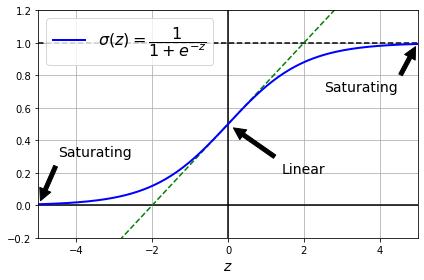

In [5]:
# extra code – this cell generates and saves Figure 11–1

import numpy as np

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

z = np.linspace(-5, 5, 200)

plt.plot([-5, 5], [0, 0], 'k-')
plt.plot([-5, 5], [1, 1], 'k--')
plt.plot([0, 0], [-0.2, 1.2], 'k-')
plt.plot([-5, 5], [-3/4, 7/4], 'g--')
plt.plot(z, sigmoid(z), "b-", linewidth=2,
         label=r"$\sigma(z) = \dfrac{1}{1+e^{-z}}$")
props = dict(facecolor='black', shrink=0.1)
plt.annotate('Saturating', xytext=(3.5, 0.7), xy=(5, 1), arrowprops=props,
             fontsize=14, ha="center")
plt.annotate('Saturating', xytext=(-3.5, 0.3), xy=(-5, 0), arrowprops=props,
             fontsize=14, ha="center")
plt.annotate('Linear', xytext=(2, 0.2), xy=(0, 0.5), arrowprops=props,
             fontsize=14, ha="center")
plt.grid(True)
plt.axis([-5, 5, -0.2, 1.2])
plt.xlabel("$z$")
plt.legend(loc="upper left", fontsize=16)

save_fig("sigmoid_saturation_plot")
plt.show()

- The derivative values are close to zero for large inputs to the sigmoid activation function
    - the inputs are weighted sums from potentially many nodes, so can have large absolute value
- For a shallow (i.e. few layers) network this is not a big problem
- For deep networks the gradients can be so small that learning effectively stops
- For back propagation the gradients from each layer are multiplied 
    - as a consequence of the chain rule
- Multiplying small numbers by small numbers soon gives very small numbers
- This is the __vanishing gradient__ problem
- We consider three common approaches to resolving this:
    - make sure that the initial weights have a suitable size
    - change the activation function(s)
    - apply __batch normalisation__ to ensure that the weighted-sum inputs are small...
    - ...so that the gradients are always relatively large 

## Xavier and He Initialization

- **Xavier initialization** works better for layers with sigmoid/tanh activation
- The idea is to select weights from a Gaussian random distribution
    - instead of uniform random from $[-1,1]$
- **He initialization** works better for layers with ReLu activation
    - small modification of the Gaussian approach
- There are many other initialisation options
- Which one (if any) is best depends on the data and the NN design 

In [6]:
dense = tf.keras.layers.Dense(50, activation="relu",
                              kernel_initializer="he_normal")

In [7]:
he_avg_init = tf.keras.initializers.VarianceScaling(scale=2., mode="fan_avg",
                                                    distribution="uniform")
dense = tf.keras.layers.Dense(50, activation="sigmoid",
                              kernel_initializer=he_avg_init)

## Nonsaturating Activation Functions

- _Saturating_ means "_restricted to a small range_" 

### Leaky ReLU

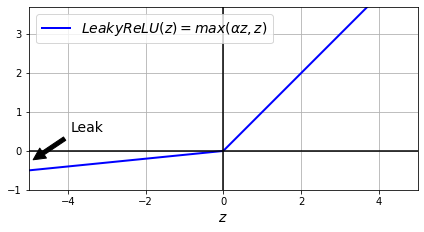

In [8]:
# extra code – this cell generates and saves Figure 11–2

def leaky_relu(z, alpha):
    return np.maximum(alpha * z, z)

z = np.linspace(-5, 5, 200)
plt.plot(z, leaky_relu(z, 0.1), "b-", linewidth=2, label=r"$LeakyReLU(z) = max(\alpha z, z)$")
plt.plot([-5, 5], [0, 0], 'k-')
plt.plot([0, 0], [-1, 3.7], 'k-')
plt.grid(True)
props = dict(facecolor='black', shrink=0.1)
plt.annotate('Leak', xytext=(-3.5, 0.5), xy=(-5, -0.3), arrowprops=props,
             fontsize=14, ha="center")
plt.xlabel("$z$")
plt.axis([-5, 5, -1, 3.7])
plt.gca().set_aspect("equal")
plt.legend()

save_fig("leaky_relu_plot")
plt.show()

In [9]:
leaky_relu = tf.keras.layers.LeakyReLU(alpha=0.2)  # defaults to alpha=0.3
dense = tf.keras.layers.Dense(50, activation=leaky_relu,
                              kernel_initializer="he_normal")

In [10]:
model = tf.keras.models.Sequential([
    # [...]  # more layers
    tf.keras.layers.Dense(50, kernel_initializer="he_normal"),  # no activation
    tf.keras.layers.LeakyReLU(alpha=0.2),  # activation as a separate layer
    # [...]  # more layers
])

### ELU

Implementing ELU in TensorFlow is trivial, just specify the activation function when building each layer, and use He initialization:

In [11]:
dense = tf.keras.layers.Dense(50, activation="elu",
                              kernel_initializer="he_normal")

### SELU

By default, the SELU hyperparameters (`scale` and `alpha`) are tuned in such a way that the mean output of each neuron remains close to 0, and the standard deviation remains close to 1 (assuming the inputs are standardized with mean 0 and standard deviation 1 too, and other constraints are respected, as explained in the book). Using this activation function, even a 1,000 layer deep neural network preserves roughly mean 0 and standard deviation 1 across all layers, avoiding the exploding/vanishing gradients problem:

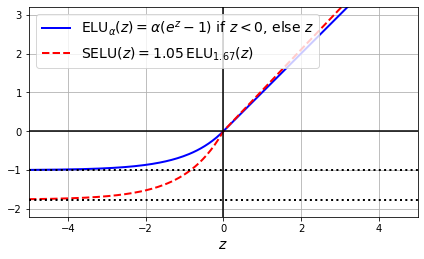

In [12]:
# extra code – this cell generates and saves Figure 11–3

from scipy.special import erfc

# alpha and scale to self normalize with mean 0 and standard deviation 1
# (see equation 14 in the paper):
alpha_0_1 = -np.sqrt(2 / np.pi) / (erfc(1 / np.sqrt(2)) * np.exp(1 / 2) - 1)
scale_0_1 = (
    (1 - erfc(1 / np.sqrt(2)) * np.sqrt(np.e))
    * np.sqrt(2 * np.pi)
    * (
        2 * erfc(np.sqrt(2)) * np.e ** 2
        + np.pi * erfc(1 / np.sqrt(2)) ** 2 * np.e
        - 2 * (2 + np.pi) * erfc(1 / np.sqrt(2)) * np.sqrt(np.e)
        + np.pi
        + 2
    ) ** (-1 / 2)
)

def elu(z, alpha=1):
    return np.where(z < 0, alpha * (np.exp(z) - 1), z)

def selu(z, scale=scale_0_1, alpha=alpha_0_1):
    return scale * elu(z, alpha)

z = np.linspace(-5, 5, 200)
plt.plot(z, elu(z), "b-", linewidth=2, label=r"ELU$_\alpha(z) = \alpha (e^z - 1)$ if $z < 0$, else $z$")
plt.plot(z, selu(z), "r--", linewidth=2, label=r"SELU$(z) = 1.05 \, $ELU$_{1.67}(z)$")
plt.plot([-5, 5], [0, 0], 'k-')
plt.plot([-5, 5], [-1, -1], 'k:', linewidth=2)
plt.plot([-5, 5], [-1.758, -1.758], 'k:', linewidth=2)
plt.plot([0, 0], [-2.2, 3.2], 'k-')
plt.grid(True)
plt.axis([-5, 5, -2.2, 3.2])
plt.xlabel("$z$")
plt.gca().set_aspect("equal")
plt.legend()

save_fig("elu_selu_plot")
plt.show()

Using SELU is straightforward:

In [13]:
dense = tf.keras.layers.Dense(50, activation="selu",
                              kernel_initializer="lecun_normal")

**Extra material – an example of a self-normalising network using SELU**

- Requirements
    - Deep stack of dense layers (a MLP)
    - **S**tacked **E**xponential **L**inear **U**nit activation in all hidden layers
- Results
    - The output of each layer tends to have mean 0 and standard deviation 1
    - In other words, a well-behaved **normal distribution**
    - Solving the vanishing gradiant problem


Let's create a neural net for Fashion MNIST with 100 hidden layers, using the SELU activation function:

In [14]:
tf.random.set_seed(42)
model = tf.keras.Sequential()
model.add(tf.keras.layers.Flatten(input_shape=[28, 28]))
for layer in range(100):
    model.add(tf.keras.layers.Dense(100, activation="selu",
                                    kernel_initializer="lecun_normal"))
model.add(tf.keras.layers.Dense(10, activation="softmax"))

In [15]:
model.compile(loss="sparse_categorical_crossentropy",
    optimizer=tf.keras.optimizers.SGD(learning_rate=0.001),
    metrics=["accuracy"])

Now let's train it. Do not forget to scale the inputs to mean 0 and standard deviation 1:

In [16]:
fashion_mnist = tf.keras.datasets.fashion_mnist.load_data()
(X_train_full, y_train_full), (X_test, y_test) = fashion_mnist
X_train, y_train = X_train_full[:-5000], y_train_full[:-5000]
X_valid, y_valid = X_train_full[-5000:], y_train_full[-5000:]
X_train, X_valid, X_test = X_train / 255, X_valid / 255, X_test / 255

In [17]:
class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

In [18]:
pixel_means = X_train.mean(axis=0, keepdims=True)
pixel_stds = X_train.std(axis=0, keepdims=True)
X_train_scaled = (X_train - pixel_means) / pixel_stds
X_valid_scaled = (X_valid - pixel_means) / pixel_stds
X_test_scaled = (X_test - pixel_means) / pixel_stds

In [19]:
%%time
history = model.fit(X_train_scaled, y_train, epochs=5,
                    validation_data=(X_valid_scaled, y_valid))

Epoch 1/5
1719/1719 [==============================] - 14s 8ms/step - loss: 1.5354 - accuracy: 0.3869 - val_loss: 0.9900 - val_accuracy: 0.6350
Epoch 2/5
1719/1719 [==============================] - 14s 8ms/step - loss: 0.9945 - accuracy: 0.6311 - val_loss: 0.8047 - val_accuracy: 0.7096
Epoch 3/5
1719/1719 [==============================] - 14s 8ms/step - loss: 0.9124 - accuracy: 0.6665 - val_loss: 0.7368 - val_accuracy: 0.7374
Epoch 4/5
1719/1719 [==============================] - 14s 8ms/step - loss: 0.7556 - accuracy: 0.7254 - val_loss: 0.7278 - val_accuracy: 0.7456
Epoch 5/5
1719/1719 [==============================] - 14s 8ms/step - loss: 0.6958 - accuracy: 0.7487 - val_loss: 0.6504 - val_accuracy: 0.7564
CPU times: user 1min 12s, sys: 2.8 s, total: 1min 15s
Wall time: 1min 10s


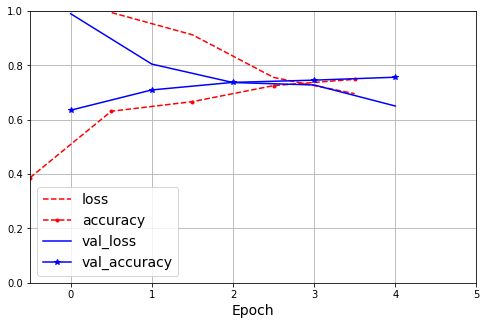

In [20]:
plt.figure(figsize=(8, 5))
for key, style in zip(history.history, ["r--", "r--.", "b-", "b-*"]):
    epochs = np.array(history.epoch) + (0 if key.startswith("val_") else -0.5)
    plt.plot(epochs, history.history[key], style, label=key)
plt.xlabel("Epoch")
plt.axis([-0.5, 5, 0., 1])
plt.legend(loc="lower left")
plt.grid()
plt.show()

The network managed to learn, despite how deep it is. Now look at what happens if we try to use the ReLU activation function instead:

In [21]:
tf.random.set_seed(42)

In [22]:
model = tf.keras.Sequential()
model.add(tf.keras.layers.Flatten(input_shape=[28, 28]))
for layer in range(100):
    model.add(tf.keras.layers.Dense(100, activation="relu",
                                    kernel_initializer="he_normal"))
model.add(tf.keras.layers.Dense(10, activation="softmax"))

In [23]:
model.compile(loss="sparse_categorical_crossentropy",
              optimizer=tf.keras.optimizers.SGD(learning_rate=0.001),
              metrics=["accuracy"])

In [24]:
%%time
history = model.fit(X_train_scaled, y_train, epochs=5,
                    validation_data=(X_valid_scaled, y_valid))

Epoch 1/5
1719/1719 [==============================] - 10s 5ms/step - loss: 2.0463 - accuracy: 0.1961 - val_loss: 1.5934 - val_accuracy: 0.3280
Epoch 2/5
1719/1719 [==============================] - 9s 5ms/step - loss: 1.6426 - accuracy: 0.3172 - val_loss: 1.2721 - val_accuracy: 0.4456
Epoch 3/5
1719/1719 [==============================] - 9s 5ms/step - loss: 1.0993 - accuracy: 0.5181 - val_loss: 1.1181 - val_accuracy: 0.5182
Epoch 4/5
1719/1719 [==============================] - 9s 5ms/step - loss: 1.0037 - accuracy: 0.5639 - val_loss: 0.8551 - val_accuracy: 0.6278
Epoch 5/5
1719/1719 [==============================] - 9s 5ms/step - loss: 1.0323 - accuracy: 0.5501 - val_loss: 0.8407 - val_accuracy: 0.6414
CPU times: user 47.5 s, sys: 2.58 s, total: 50.1 s
Wall time: 44.9 s


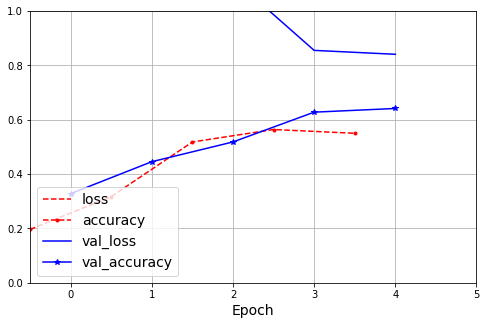

In [25]:
plt.figure(figsize=(8, 5))
for key, style in zip(history.history, ["r--", "r--.", "b-", "b-*"]):
    epochs = np.array(history.epoch) + (0 if key.startswith("val_") else -0.5)
    plt.plot(epochs, history.history[key], style, label=key)
plt.xlabel("Epoch")
plt.axis([-0.5, 5, 0., 1])
plt.legend(loc="lower left")
plt.grid()
plt.show()

Not great at all, we suffered from the vanishing/exploding gradients problem.

### GELU, Swish and Mish

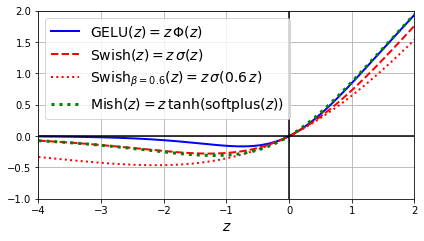

In [26]:
# extra code – this cell generates and saves Figure 11–4

def swish(z, beta=1):
    return z * sigmoid(beta * z)

def approx_gelu(z):
    return swish(z, beta=1.702)

def softplus(z):
    return np.log(1 + np.exp(z))

def mish(z):
    return z * np.tanh(softplus(z))

z = np.linspace(-4, 2, 200)

beta = 0.6
plt.plot(z, approx_gelu(z), "b-", linewidth=2,
         label=r"GELU$(z) = z\,\Phi(z)$")
plt.plot(z, swish(z), "r--", linewidth=2,
         label=r"Swish$(z) = z\,\sigma(z)$")
plt.plot(z, swish(z, beta), "r:", linewidth=2,
         label=fr"Swish$_{{\beta={beta}}}(z)=z\,\sigma({beta}\,z)$")
plt.plot(z, mish(z), "g:", linewidth=3,
         label=fr"Mish$(z) = z\,\tanh($softplus$(z))$")
plt.plot([-4, 2], [0, 0], 'k-')
plt.plot([0, 0], [-2.2, 3.2], 'k-')
plt.grid(True)
plt.axis([-4, 2, -1, 2])
plt.gca().set_aspect("equal")
plt.xlabel("$z$")
plt.legend(loc="upper left")

save_fig("gelu_swish_mish_plot")
plt.show()

## Activation Summary

- We now have a set of up-to-date options
    - each with strengths and weaknesses
- Which should we use?
- ReLU is still a good default for many tasks
    - and has excellent library support
- Swish is a good alternative
    - and can be improved by varying the $\beta$ hyperparameter
- For deep models, SELU will avoid vanishing gradients
    - but only id the requirements are met
- The correct anser is data and problem dependent
    - Recall: frame the problem, get the data, explore models
- So grid search (or a random version) should be performed

# Batch Normalization

- Re-centre and re-scale the data at the start of each epoch
- The aim is faster and more stable convergence 
    - and this can work very well for some data & NN architectures
- Of course, there is more computational effort, but this may be offset by requiring fewer epochs (or fewer layers)

In [27]:
# extra code - clear the name counters and set the random seed
tf.keras.backend.clear_session()
tf.random.set_seed(42)

In [28]:
model = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=[28, 28]),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dense(300, activation="relu",
                          kernel_initializer="he_normal"),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dense(100, activation="relu",
                          kernel_initializer="he_normal"),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dense(10, activation="softmax")
])

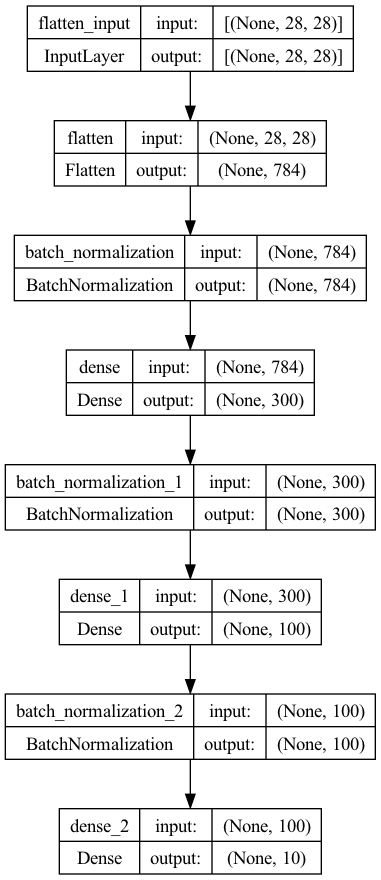

In [29]:
tf.keras.utils.plot_model(model, show_shapes=True)

In [30]:
[(var.name, var.trainable) for var in model.layers[1].variables]

[('batch_normalization/gamma:0', True),
 ('batch_normalization/beta:0', True),
 ('batch_normalization/moving_mean:0', False),
 ('batch_normalization/moving_variance:0', False)]

In [31]:
%%time
# extra code – just show that the model works! 😊

model.compile(loss="sparse_categorical_crossentropy", optimizer="sgd",
              metrics="accuracy")
model.fit(X_train, y_train, epochs=2, validation_data=(X_valid, y_valid))

Epoch 1/2
1719/1719 [==============================] - 2s 1ms/step - loss: 0.5519 - accuracy: 0.8092 - val_loss: 0.3963 - val_accuracy: 0.8606
Epoch 2/2
1719/1719 [==============================] - 2s 1ms/step - loss: 0.4062 - accuracy: 0.8559 - val_loss: 0.3617 - val_accuracy: 0.8710
CPU times: user 7.31 s, sys: 2.01 s, total: 9.31 s
Wall time: 4.84 s


Sometimes applying BN before the activation function works better (there's a debate on this topic). Moreover, the layer before a `BatchNormalization` layer does not need to have bias terms, since the `BatchNormalization` layer some as well, it would be a waste of parameters, so you can set `use_bias=False` when creating those layers:

In [32]:
# extra code - clear the name counters and set the random seed
tf.keras.backend.clear_session()
tf.random.set_seed(42)

In [33]:
model = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=[28, 28]),
    tf.keras.layers.Dense(300, kernel_initializer="he_normal", use_bias=False),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation("relu"),
    tf.keras.layers.Dense(100, kernel_initializer="he_normal", use_bias=False),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation("relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])

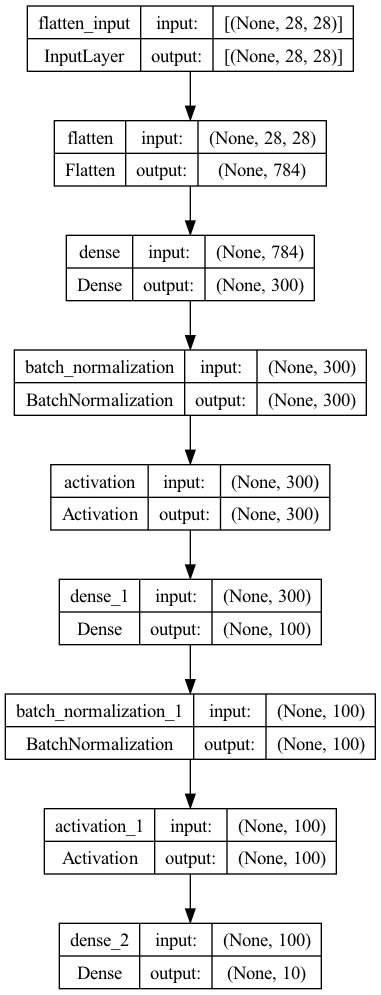

In [34]:
tf.keras.utils.plot_model(model, show_shapes=True)

In [35]:
%%time
# extra code – just show that the model works! 😊
model.compile(loss="sparse_categorical_crossentropy", optimizer="sgd",
              metrics="accuracy")
model.fit(X_train, y_train, epochs=2, validation_data=(X_valid, y_valid))

Epoch 1/2
1719/1719 [==============================] - 2s 1ms/step - loss: 0.6011 - accuracy: 0.7990 - val_loss: 0.4400 - val_accuracy: 0.8422
Epoch 2/2
1719/1719 [==============================] - 2s 1ms/step - loss: 0.4272 - accuracy: 0.8512 - val_loss: 0.3809 - val_accuracy: 0.8626
CPU times: user 5.51 s, sys: 1.3 s, total: 6.81 s
Wall time: 3.83 s


## Gradient Clipping

- Gradients can become too large as well as too small
- This is the __exploding gradient__ problem
    - often caused by trying to avoid a vanishing gradient!
- A simple approach is to check error gradient values against a threshold value and clip them (i.e. set to that threshold value) if the threshold is exceeded
- Another approach (that we don't look at here) is __weight normalisation__
    - use $\ell^1$ or $\ell^2$ norm penalisation of weight values

All `tf.keras.optimizers` accept `clipnorm` or `clipvalue` arguments:

In [36]:
optimizer = tf.keras.optimizers.SGD(clipvalue=1.0)
model.compile(loss="sparse_categorical_crossentropy", optimizer=optimizer)

In [37]:
optimizer = tf.keras.optimizers.SGD(clipnorm=1.0)
model.compile(loss="sparse_categorical_crossentropy", optimizer=optimizer)

## Reusing Pretrained Layers

### Reusing a Keras model

Let's split the fashion MNIST training set in two:
* `X_train_A`: all images of all items except for T-shirts/tops and pullovers (classes 0 and 2).
* `X_train_B`: a much smaller training set of just the first 200 images of T-shirts/tops and pullovers.

The validation set and the test set are also split this way, but without restricting the number of images.

We will train a model on set A (classification task with 8 classes), and try to reuse it to tackle set B (binary classification). We hope to transfer a little bit of knowledge from task A to task B, since classes in set A (trousers, dresses, coats, sandals, shirts, sneakers, bags, and ankle boots) are somewhat similar to classes in set B (T-shirts/tops and pullovers). However, since we are using `Dense` layers, only patterns that occur at the same location can be reused (in contrast, convolutional layers will transfer much better, since learned patterns can be detected anywhere on the image, as we will see in the chapter 14).

In [38]:
%%time
# extra code – split Fashion MNIST into tasks A and B, then train and save
#              model A to "my_model_A".

pos_class_id = class_names.index("Pullover")
neg_class_id = class_names.index("T-shirt/top")

def split_dataset(X, y):
    y_for_B = (y == pos_class_id) | (y == neg_class_id)
    y_A = y[~y_for_B]
    y_B = (y[y_for_B] == pos_class_id).astype(np.float32)
    old_class_ids = list(set(range(10)) - set([neg_class_id, pos_class_id]))
    for old_class_id, new_class_id in zip(old_class_ids, range(8)):
        y_A[y_A == old_class_id] = new_class_id  # reorder class ids for A
    return ((X[~y_for_B], y_A), (X[y_for_B], y_B))

(X_train_A, y_train_A), (X_train_B, y_train_B) = split_dataset(X_train, y_train)
(X_valid_A, y_valid_A), (X_valid_B, y_valid_B) = split_dataset(X_valid, y_valid)
(X_test_A, y_test_A), (X_test_B, y_test_B) = split_dataset(X_test, y_test)
X_train_B = X_train_B[:200]
y_train_B = y_train_B[:200]

tf.random.set_seed(42)

model_A = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=[28, 28]),
    tf.keras.layers.Dense(100, activation="relu",
                          kernel_initializer="he_normal"),
    tf.keras.layers.Dense(100, activation="relu",
                          kernel_initializer="he_normal"),
    tf.keras.layers.Dense(100, activation="relu",
                          kernel_initializer="he_normal"),
    tf.keras.layers.Dense(8, activation="softmax")
])

model_A.compile(loss="sparse_categorical_crossentropy",
                optimizer=tf.keras.optimizers.SGD(learning_rate=0.001),
                metrics=["accuracy"])
history = model_A.fit(X_train_A, y_train_A, epochs=20,
                      validation_data=(X_valid_A, y_valid_A))
model_A.save("my_model_A")

Epoch 1/20
1376/1376 [==============================] - 1s 668us/step - loss: 1.1690 - accuracy: 0.6662 - val_loss: 0.6993 - val_accuracy: 0.7932
Epoch 2/20
1376/1376 [==============================] - 1s 625us/step - loss: 0.5952 - accuracy: 0.8200 - val_loss: 0.5117 - val_accuracy: 0.8366
Epoch 3/20
1376/1376 [==============================] - 1s 618us/step - loss: 0.4784 - accuracy: 0.8497 - val_loss: 0.4422 - val_accuracy: 0.8576
Epoch 4/20
1376/1376 [==============================] - 1s 620us/step - loss: 0.4225 - accuracy: 0.8644 - val_loss: 0.4015 - val_accuracy: 0.8691
Epoch 5/20
1376/1376 [==============================] - 1s 619us/step - loss: 0.3876 - accuracy: 0.8739 - val_loss: 0.3749 - val_accuracy: 0.8749
Epoch 6/20
1376/1376 [==============================] - 1s 620us/step - loss: 0.3627 - accuracy: 0.8801 - val_loss: 0.3553 - val_accuracy: 0.8814
Epoch 7/20
1376/1376 [==============================] - 1s 621us/step - loss: 0.3445 - accuracy: 0.8846 - val_loss: 0.3401 -

INFO:tensorflow:Assets written to: my_model_A/assets


CPU times: user 22.7 s, sys: 5.29 s, total: 28 s
Wall time: 17.6 s


In [39]:
%%time
# extra code – train and evaluate model B, without reusing model A

tf.random.set_seed(42)
model_B = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=[28, 28]),
    tf.keras.layers.Dense(100, activation="relu",
                          kernel_initializer="he_normal"),
    tf.keras.layers.Dense(100, activation="relu",
                          kernel_initializer="he_normal"),
    tf.keras.layers.Dense(100, activation="relu",
                          kernel_initializer="he_normal"),
    tf.keras.layers.Dense(1, activation="sigmoid")
])

model_B.compile(loss="binary_crossentropy",
                optimizer=tf.keras.optimizers.SGD(learning_rate=0.001),
                metrics=["accuracy"])
history = model_B.fit(X_train_B, y_train_B, epochs=20,
                      validation_data=(X_valid_B, y_valid_B))
model_B.evaluate(X_test_B, y_test_B)

Epoch 1/20
7/7 [==============================] - 0s 13ms/step - loss: 0.6603 - accuracy: 0.6150 - val_loss: 0.6510 - val_accuracy: 0.6142
Epoch 2/20
7/7 [==============================] - 0s 5ms/step - loss: 0.6388 - accuracy: 0.6900 - val_loss: 0.6324 - val_accuracy: 0.6677
Epoch 3/20
7/7 [==============================] - 0s 5ms/step - loss: 0.6189 - accuracy: 0.7400 - val_loss: 0.6151 - val_accuracy: 0.6973
Epoch 4/20
7/7 [==============================] - 0s 4ms/step - loss: 0.5989 - accuracy: 0.7650 - val_loss: 0.5997 - val_accuracy: 0.7310
Epoch 5/20
7/7 [==============================] - 0s 4ms/step - loss: 0.5824 - accuracy: 0.7850 - val_loss: 0.5841 - val_accuracy: 0.7765
Epoch 6/20
7/7 [==============================] - 0s 5ms/step - loss: 0.5658 - accuracy: 0.7850 - val_loss: 0.5702 - val_accuracy: 0.7953
Epoch 7/20
7/7 [==============================] - 0s 4ms/step - loss: 0.5506 - accuracy: 0.8100 - val_loss: 0.5566 - val_accuracy: 0.8289
Epoch 8/20
7/7 [=================

[0.45001089572906494, 0.8805000185966492]

Model B reaches 91.85% accuracy on the test set. Now let's try reusing the pretrained model A.

- Now load model A
- Define model B on A as having the same layers as model A, aprt from the last one
- This was the output layer, which we need to redefine for a classification problem
- So we add a sigmoid final layer that returns a single probability

In [40]:
model_A = tf.keras.models.load_model("my_model_A")
model_B_on_A = tf.keras.Sequential(model_A.layers[:-1])
model_B_on_A.add(tf.keras.layers.Dense(1, activation="sigmoid"))

Note that `model_B_on_A` and `model_A` actually share layers now, so when we train one, it will update both models. If we want to avoid that, we need to build `model_B_on_A` on top of a *clone* of `model_A`:

In [41]:
model_A_clone = tf.keras.models.clone_model(model_A) 
model_A_clone.set_weights(model_A.get_weights())

In [42]:
# extra code – creating model_B_on_A just like in the previous cell
model_B_on_A = tf.keras.Sequential(model_A_clone.layers[:-1])
model_B_on_A.add(tf.keras.layers.Dense(1, activation="sigmoid"))

- Compile the model without training/learning any new weights
- Then retrain and validate on the X and y data

In [43]:
for layer in model_B_on_A.layers[:-1]:
    layer.trainable = False

optimizer = tf.keras.optimizers.SGD(learning_rate=0.001)
model_B_on_A.compile(loss="binary_crossentropy", optimizer=optimizer,
                     metrics=["accuracy"])

In [44]:
%%time
history = model_B_on_A.fit(X_train_B, y_train_B, epochs=4,
                           validation_data=(X_valid_B, y_valid_B))

for layer in model_B_on_A.layers[:-1]:
    layer.trainable = True

optimizer = tf.keras.optimizers.SGD(learning_rate=0.001)
model_B_on_A.compile(loss="binary_crossentropy", optimizer=optimizer,
                     metrics=["accuracy"])
history = model_B_on_A.fit(X_train_B, y_train_B, epochs=16,
                           validation_data=(X_valid_B, y_valid_B))

Epoch 1/4
7/7 [==============================] - 0s 35ms/step - loss: 4.5757 - accuracy: 0.5550 - val_loss: 4.1602 - val_accuracy: 0.5153
Epoch 2/4
7/7 [==============================] - 0s 4ms/step - loss: 3.5378 - accuracy: 0.5550 - val_loss: 3.1286 - val_accuracy: 0.5153
Epoch 3/4
7/7 [==============================] - 0s 5ms/step - loss: 2.5864 - accuracy: 0.5550 - val_loss: 2.2144 - val_accuracy: 0.5153
Epoch 4/4
7/7 [==============================] - 0s 4ms/step - loss: 1.7552 - accuracy: 0.5550 - val_loss: 1.3982 - val_accuracy: 0.5153


Epoch 1/16
7/7 [==============================] - 0s 12ms/step - loss: 0.9353 - accuracy: 0.5550 - val_loss: 0.6800 - val_accuracy: 0.5529
Epoch 2/16
7/7 [==============================] - 0s 5ms/step - loss: 0.6601 - accuracy: 0.6000 - val_loss: 0.6283 - val_accuracy: 0.6746
Epoch 3/16
7/7 [==============================] - 0s 5ms/step - loss: 0.6135 - accuracy: 0.7100 - val_loss: 0.6019 - val_accuracy: 0.6914
Epoch 4/16
7/7 [==============================] - 0s 4ms/step - loss: 0.5603 - accuracy: 0.7900 - val_loss: 0.5564 - val_accuracy: 0.7774
Epoch 5/16
7/7 [==============================] - 0s 4ms/step - loss: 0.5237 - accuracy: 0.8400 - val_loss: 0.5179 - val_accuracy: 0.8457
Epoch 6/16
7/7 [==============================] - 0s 5ms/step - loss: 0.4895 - accuracy: 0.8850 - val_loss: 0.4875 - val_accuracy: 0.8843
Epoch 7/16
7/7 [==============================] - 0s 4ms/step - loss: 0.4606 - accuracy: 0.9150 - val_loss: 0.4678 - val_accuracy: 0.8773
Epoch 8/16
7/7 [=================

So, what's the final verdict?

In [45]:
model_B_on_A.evaluate(X_test_B, y_test_B)

63/63 [==============================] - 0s 439us/step - loss: 0.3293 - accuracy: 0.9420


[0.329335480928421, 0.9419999718666077]

Great! We got a bit of transfer: the model's accuracy went up 2 percentage points, from 91.85% to 93.85%. This means the error rate dropped by almost 25%:

In [46]:
1 - (100 - 93.85) / (100 - 91.85)

0.24539877300613477

# Faster Optimizers

- The details are beyond the scope of the module
- Optimizers should 
    - be efficient
    - avoid saddle points
    - avoid local minima
- These desirable features are often mutually exclusive
- The design and empirical evaluation of optimizers is a large area of research

### Model comparison methodology
- We'll be trying out many options for learning in the rest of this topic
- Rather than define the same model many times, we write a function
- This is good coding practice:
    1. Any part of code that is written multiple times should be a function
    2. We guarantee that any comparisons are valid, as the only change is our current aspect
    3. There is one plave to change the model (layers, activation, etc)

In [47]:
# extra code – a little function to test an optimizer on Fashion MNIST

def build_model(seed=42):
    tf.random.set_seed(seed)
    return tf.keras.Sequential([
        tf.keras.layers.Flatten(input_shape=[28, 28]),
        tf.keras.layers.Dense(100, activation="relu",
                              kernel_initializer="he_normal"),
        tf.keras.layers.Dense(100, activation="relu",
                              kernel_initializer="he_normal"),
        tf.keras.layers.Dense(100, activation="relu",
                              kernel_initializer="he_normal"),
        tf.keras.layers.Dense(10, activation="softmax")
    ])

def build_and_train_model(optimizer):
    model = build_model()
    model.compile(loss="sparse_categorical_crossentropy", optimizer=optimizer,
                  metrics=["accuracy"])
    return model.fit(X_train, y_train, epochs=10,
                     validation_data=(X_valid, y_valid))

In [48]:
optimizer = tf.keras.optimizers.SGD(learning_rate=0.001, momentum=0.9)

In [49]:
%%time
history_sgd = build_and_train_model(optimizer)  # extra code

Epoch 1/10
1719/1719 [==============================] - 1s 748us/step - loss: 0.7044 - accuracy: 0.7592 - val_loss: 0.5023 - val_accuracy: 0.8184
Epoch 2/10
1719/1719 [==============================] - 1s 715us/step - loss: 0.4674 - accuracy: 0.8344 - val_loss: 0.4494 - val_accuracy: 0.8388
Epoch 3/10
1719/1719 [==============================] - 1s 712us/step - loss: 0.4220 - accuracy: 0.8508 - val_loss: 0.4130 - val_accuracy: 0.8504
Epoch 4/10
1719/1719 [==============================] - 1s 711us/step - loss: 0.3968 - accuracy: 0.8598 - val_loss: 0.3881 - val_accuracy: 0.8640
Epoch 5/10
1719/1719 [==============================] - 1s 710us/step - loss: 0.3744 - accuracy: 0.8666 - val_loss: 0.3717 - val_accuracy: 0.8606
Epoch 6/10
1719/1719 [==============================] - 1s 710us/step - loss: 0.3604 - accuracy: 0.8716 - val_loss: 0.3730 - val_accuracy: 0.8630
Epoch 7/10
1719/1719 [==============================] - 1s 710us/step - loss: 0.3447 - accuracy: 0.8759 - val_loss: 0.3710 -

## Momentum optimization

In [50]:
optimizer = tf.keras.optimizers.SGD(learning_rate=0.001, momentum=0.9)

In [51]:
%%time
history_momentum = build_and_train_model(optimizer)  # extra code

Epoch 1/10
1719/1719 [==============================] - 1s 720us/step - loss: 0.6924 - accuracy: 0.7660 - val_loss: 0.5098 - val_accuracy: 0.8144
Epoch 2/10
1719/1719 [==============================] - 1s 683us/step - loss: 0.4639 - accuracy: 0.8360 - val_loss: 0.4507 - val_accuracy: 0.8374
Epoch 3/10
1719/1719 [==============================] - 1s 681us/step - loss: 0.4188 - accuracy: 0.8515 - val_loss: 0.4122 - val_accuracy: 0.8520
Epoch 4/10
1719/1719 [==============================] - 1s 680us/step - loss: 0.3925 - accuracy: 0.8607 - val_loss: 0.3840 - val_accuracy: 0.8632
Epoch 5/10
1719/1719 [==============================] - 1s 677us/step - loss: 0.3707 - accuracy: 0.8670 - val_loss: 0.3653 - val_accuracy: 0.8674
Epoch 6/10
1719/1719 [==============================] - 1s 682us/step - loss: 0.3583 - accuracy: 0.8701 - val_loss: 0.3666 - val_accuracy: 0.8648
Epoch 7/10
1719/1719 [==============================] - 1s 680us/step - loss: 0.3426 - accuracy: 0.8753 - val_loss: 0.3560 -

## Nesterov Accelerated Gradient

In [52]:
optimizer = tf.keras.optimizers.SGD(learning_rate=0.001, momentum=0.9,
                                    nesterov=True)

In [53]:
%%time
history_nesterov = build_and_train_model(optimizer)  # extra code

Epoch 1/10
1719/1719 [==============================] - 1s 757us/step - loss: 0.7021 - accuracy: 0.7625 - val_loss: 0.4942 - val_accuracy: 0.8276
Epoch 2/10
1719/1719 [==============================] - 1s 720us/step - loss: 0.4628 - accuracy: 0.8377 - val_loss: 0.4449 - val_accuracy: 0.8382
Epoch 3/10
1719/1719 [==============================] - 1s 717us/step - loss: 0.4188 - accuracy: 0.8509 - val_loss: 0.3993 - val_accuracy: 0.8566
Epoch 4/10
1719/1719 [==============================] - 1s 719us/step - loss: 0.3934 - accuracy: 0.8613 - val_loss: 0.3864 - val_accuracy: 0.8630
Epoch 5/10
1719/1719 [==============================] - 1s 719us/step - loss: 0.3736 - accuracy: 0.8676 - val_loss: 0.3723 - val_accuracy: 0.8640
Epoch 6/10
1719/1719 [==============================] - 1s 728us/step - loss: 0.3592 - accuracy: 0.8705 - val_loss: 0.3811 - val_accuracy: 0.8660
Epoch 7/10
1719/1719 [==============================] - 1s 718us/step - loss: 0.3443 - accuracy: 0.8759 - val_loss: 0.3793 -

## AdaGrad

In [54]:
optimizer = tf.keras.optimizers.Adagrad(learning_rate=0.001)

In [55]:
%%time
history_adagrad = build_and_train_model(optimizer)  # extra code

Epoch 1/10
1719/1719 [==============================] - 1s 753us/step - loss: 1.0076 - accuracy: 0.6754 - val_loss: 0.6624 - val_accuracy: 0.7782
Epoch 2/10
1719/1719 [==============================] - 1s 713us/step - loss: 0.6133 - accuracy: 0.7950 - val_loss: 0.5681 - val_accuracy: 0.8084
Epoch 3/10
1719/1719 [==============================] - 1s 714us/step - loss: 0.5506 - accuracy: 0.8144 - val_loss: 0.5283 - val_accuracy: 0.8184
Epoch 4/10
1719/1719 [==============================] - 1s 715us/step - loss: 0.5184 - accuracy: 0.8255 - val_loss: 0.5051 - val_accuracy: 0.8258
Epoch 5/10
1719/1719 [==============================] - 1s 713us/step - loss: 0.4972 - accuracy: 0.8316 - val_loss: 0.4885 - val_accuracy: 0.8294
Epoch 6/10
1719/1719 [==============================] - 1s 717us/step - loss: 0.4818 - accuracy: 0.8357 - val_loss: 0.4788 - val_accuracy: 0.8314
Epoch 7/10
1719/1719 [==============================] - 1s 713us/step - loss: 0.4699 - accuracy: 0.8387 - val_loss: 0.4651 -

## RMSProp

In [56]:
optimizer = tf.keras.optimizers.RMSprop(learning_rate=0.001, rho=0.9)

In [57]:
%%time
history_rmsprop = build_and_train_model(optimizer)  # extra code

Epoch 1/10
1719/1719 [==============================] - 2s 913us/step - loss: 0.5113 - accuracy: 0.8156 - val_loss: 0.3956 - val_accuracy: 0.8530
Epoch 2/10
1719/1719 [==============================] - 2s 887us/step - loss: 0.3951 - accuracy: 0.8590 - val_loss: 0.4447 - val_accuracy: 0.8350
Epoch 3/10
1719/1719 [==============================] - 2s 891us/step - loss: 0.3694 - accuracy: 0.8685 - val_loss: 0.3691 - val_accuracy: 0.8768
Epoch 4/10
1719/1719 [==============================] - 2s 881us/step - loss: 0.3602 - accuracy: 0.8762 - val_loss: 0.4045 - val_accuracy: 0.8654
Epoch 5/10
1719/1719 [==============================] - 2s 885us/step - loss: 0.3582 - accuracy: 0.8764 - val_loss: 0.4053 - val_accuracy: 0.8622
Epoch 6/10
1719/1719 [==============================] - 2s 889us/step - loss: 0.3564 - accuracy: 0.8794 - val_loss: 0.4361 - val_accuracy: 0.8634
Epoch 7/10
1719/1719 [==============================] - 2s 888us/step - loss: 0.3608 - accuracy: 0.8795 - val_loss: 0.4600 -

## Adam Optimization

In [58]:
optimizer = tf.keras.optimizers.Adam(learning_rate=0.001, beta_1=0.9,
                                     beta_2=0.999)

In [59]:
%%time
history_adam = build_and_train_model(optimizer)  # extra code

Epoch 1/10
1719/1719 [==============================] - 2s 893us/step - loss: 0.5013 - accuracy: 0.8212 - val_loss: 0.4423 - val_accuracy: 0.8266
Epoch 2/10
1719/1719 [==============================] - 1s 852us/step - loss: 0.3779 - accuracy: 0.8619 - val_loss: 0.3869 - val_accuracy: 0.8470
Epoch 3/10
1719/1719 [==============================] - 1s 851us/step - loss: 0.3425 - accuracy: 0.8740 - val_loss: 0.3601 - val_accuracy: 0.8684
Epoch 4/10
1719/1719 [==============================] - 1s 848us/step - loss: 0.3180 - accuracy: 0.8833 - val_loss: 0.3527 - val_accuracy: 0.8732
Epoch 5/10
1719/1719 [==============================] - 1s 847us/step - loss: 0.2988 - accuracy: 0.8892 - val_loss: 0.3277 - val_accuracy: 0.8784
Epoch 6/10
1719/1719 [==============================] - 1s 847us/step - loss: 0.2850 - accuracy: 0.8934 - val_loss: 0.3283 - val_accuracy: 0.8770
Epoch 7/10
1719/1719 [==============================] - 1s 846us/step - loss: 0.2707 - accuracy: 0.8982 - val_loss: 0.3475 -

**Adamax Optimization**

In [60]:
optimizer = tf.keras.optimizers.Adamax(learning_rate=0.001, beta_1=0.9,
                                       beta_2=0.999)

In [61]:
%%time
history_adamax = build_and_train_model(optimizer)  # extra code

Epoch 1/10
1719/1719 [==============================] - 2s 830us/step - loss: 0.5386 - accuracy: 0.8115 - val_loss: 0.4540 - val_accuracy: 0.8334
Epoch 2/10
1719/1719 [==============================] - 1s 794us/step - loss: 0.4006 - accuracy: 0.8570 - val_loss: 0.4026 - val_accuracy: 0.8548
Epoch 3/10
1719/1719 [==============================] - 1s 795us/step - loss: 0.3626 - accuracy: 0.8690 - val_loss: 0.3609 - val_accuracy: 0.8702
Epoch 4/10
1719/1719 [==============================] - 1s 799us/step - loss: 0.3378 - accuracy: 0.8780 - val_loss: 0.3408 - val_accuracy: 0.8742
Epoch 5/10
1719/1719 [==============================] - 1s 827us/step - loss: 0.3156 - accuracy: 0.8852 - val_loss: 0.3288 - val_accuracy: 0.8756
Epoch 6/10
1719/1719 [==============================] - 1s 792us/step - loss: 0.3011 - accuracy: 0.8899 - val_loss: 0.3309 - val_accuracy: 0.8780
Epoch 7/10
1719/1719 [==============================] - 1s 794us/step - loss: 0.2877 - accuracy: 0.8934 - val_loss: 0.3407 -

**Nadam Optimization**

In [62]:
optimizer = tf.keras.optimizers.Nadam(learning_rate=0.001, beta_1=0.9,
                                      beta_2=0.999)

In [63]:
%%time
history_nadam = build_and_train_model(optimizer)  # extra code

Epoch 1/10
1719/1719 [==============================] - 2s 1ms/step - loss: 0.4872 - accuracy: 0.8269 - val_loss: 0.4092 - val_accuracy: 0.8450
Epoch 2/10
1719/1719 [==============================] - 2s 1ms/step - loss: 0.3641 - accuracy: 0.8656 - val_loss: 0.3770 - val_accuracy: 0.8536
Epoch 3/10
1719/1719 [==============================] - 2s 1ms/step - loss: 0.3286 - accuracy: 0.8790 - val_loss: 0.3504 - val_accuracy: 0.8740
Epoch 4/10
1719/1719 [==============================] - 2s 1ms/step - loss: 0.3064 - accuracy: 0.8883 - val_loss: 0.3488 - val_accuracy: 0.8742
Epoch 5/10
1719/1719 [==============================] - 2s 1ms/step - loss: 0.2896 - accuracy: 0.8924 - val_loss: 0.3279 - val_accuracy: 0.8800
Epoch 6/10
1719/1719 [==============================] - 2s 1ms/step - loss: 0.2759 - accuracy: 0.8973 - val_loss: 0.3937 - val_accuracy: 0.8710
Epoch 7/10
1719/1719 [==============================] - 2s 1ms/step - loss: 0.2629 - accuracy: 0.8999 - val_loss: 0.3470 - val_accuracy:

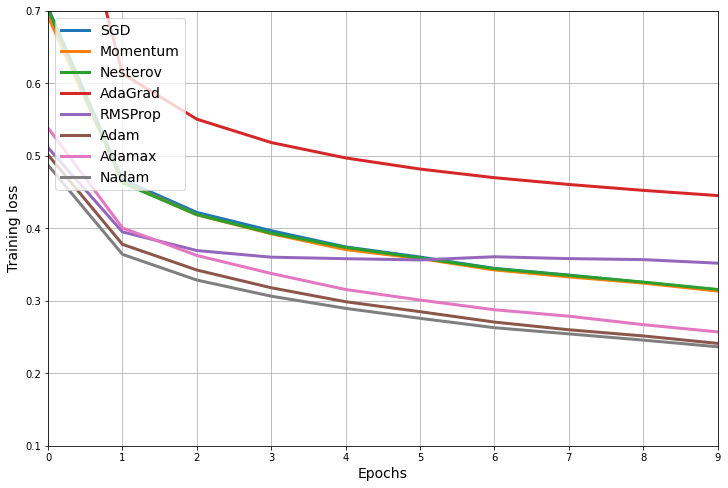

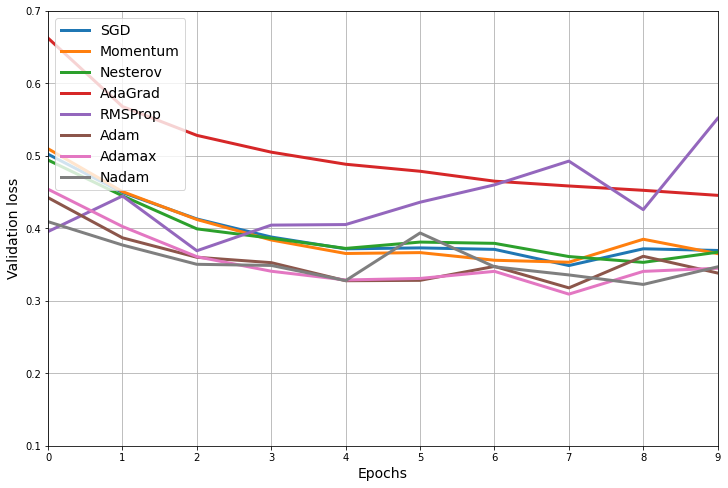

In [64]:
# extra code – visualize the learning curves of all the optimizers

for loss in ("loss", "val_loss"):
    plt.figure(figsize=(12, 8))
    opt_names = "SGD Momentum Nesterov AdaGrad RMSProp Adam Adamax Nadam"
    for history, opt_name in zip((history_sgd, history_momentum, history_nesterov,
                                  history_adagrad, history_rmsprop, history_adam,
                                  history_adamax, history_nadam),
                                 opt_names.split()):
        plt.plot(history.history[loss], label=f"{opt_name}", linewidth=3)

    plt.grid()
    plt.xlabel("Epochs")
    plt.ylabel({"loss": "Training loss", "val_loss": "Validation loss"}[loss])
    plt.legend(loc="upper left")
    plt.axis([0, 9, 0.1, 0.7])
    plt.show()

## Learning Rate Scheduling

- Finding a good learning rate is a complex task
- Way too high will give increasing loss
- Too high will be suboptimal
- Too low will take too long
- There is a "Goldilocks value" that gives low loss after a small number of epochs
- But there is now need to keep the rate constant across epochs
- Strategy 1:
    1. Start large
    2. Reduce when training stops making fast progress
- Strategy 2:
    1. Start low
    2. Increase if taking too long
    3. Reduce as before


### Power Scheduling

```lr = lr0 / (1 + steps / s)**c```
* Keras uses `c=1` and `s = 1 / decay`

In [65]:
optimizer = tf.keras.optimizers.legacy.SGD(learning_rate=0.01, decay=1e-4)

In [66]:
%%time
history_power_scheduling = build_and_train_model(optimizer)  # extra code

Epoch 1/10
1719/1719 [==============================] - 1s 730us/step - loss: 0.6766 - accuracy: 0.7660 - val_loss: 0.5018 - val_accuracy: 0.8212
Epoch 2/10
1719/1719 [==============================] - 1s 679us/step - loss: 0.4722 - accuracy: 0.8351 - val_loss: 0.4579 - val_accuracy: 0.8354
Epoch 3/10
1719/1719 [==============================] - 1s 677us/step - loss: 0.4277 - accuracy: 0.8495 - val_loss: 0.4230 - val_accuracy: 0.8506
Epoch 4/10
1719/1719 [==============================] - 1s 684us/step - loss: 0.4043 - accuracy: 0.8579 - val_loss: 0.3893 - val_accuracy: 0.8596
Epoch 5/10
1719/1719 [==============================] - 1s 686us/step - loss: 0.3853 - accuracy: 0.8634 - val_loss: 0.3830 - val_accuracy: 0.8596
Epoch 6/10
1719/1719 [==============================] - 1s 693us/step - loss: 0.3718 - accuracy: 0.8673 - val_loss: 0.3896 - val_accuracy: 0.8584
Epoch 7/10
1719/1719 [==============================] - 1s 695us/step - loss: 0.3625 - accuracy: 0.8704 - val_loss: 0.3682 -

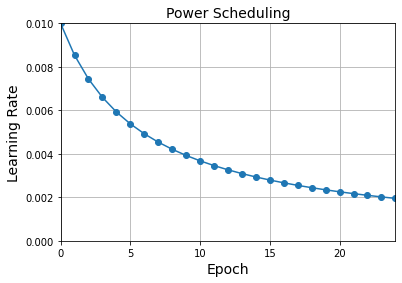

In [67]:
# extra code – this cell plots power scheduling

import math

learning_rate = 0.01
decay = 1e-4
batch_size = 32
n_steps_per_epoch = math.ceil(len(X_train) / batch_size)
n_epochs = 25

epochs = np.arange(n_epochs)
lrs = learning_rate / (1 + decay * epochs * n_steps_per_epoch)

plt.plot(epochs, lrs,  "o-")
plt.axis([0, n_epochs - 1, 0, 0.01])
plt.xlabel("Epoch")
plt.ylabel("Learning Rate")
plt.title("Power Scheduling", fontsize=14)
plt.grid(True)
plt.show()

### Exponential Scheduling

```lr = lr0 * 0.1 ** (epoch / s)```

In [68]:
def exponential_decay_fn(epoch):
    return 0.01 * 0.1 ** (epoch / 20)

In [69]:
def exponential_decay(lr0, s):
    def exponential_decay_fn(epoch):
        return lr0 * 0.1 ** (epoch / s)
    return exponential_decay_fn

exponential_decay_fn = exponential_decay(lr0=0.01, s=20)

In [70]:
# extra code – build and compile a model for Fashion MNIST

tf.random.set_seed(42)
model = build_model()
optimizer = tf.keras.optimizers.legacy.SGD(learning_rate=0.001)
model.compile(loss="sparse_categorical_crossentropy", optimizer=optimizer,
              metrics=["accuracy"])

In [71]:
%%time
lr_scheduler = tf.keras.callbacks.LearningRateScheduler(exponential_decay_fn)
history = model.fit(X_train, y_train, epochs=n_epochs,
                    validation_data=(X_valid, y_valid),
                    callbacks=[lr_scheduler])

Epoch 1/25
1719/1719 [==============================] - 1s 669us/step - loss: 0.6693 - accuracy: 0.7693 - val_loss: 0.4769 - val_accuracy: 0.8348 - lr: 0.0100
Epoch 2/25
1719/1719 [==============================] - 1s 621us/step - loss: 0.4624 - accuracy: 0.8352 - val_loss: 0.4366 - val_accuracy: 0.8424 - lr: 0.0089
Epoch 3/25
1719/1719 [==============================] - 1s 615us/step - loss: 0.4171 - accuracy: 0.8516 - val_loss: 0.4100 - val_accuracy: 0.8556 - lr: 0.0079
Epoch 4/25
1719/1719 [==============================] - 1s 622us/step - loss: 0.3929 - accuracy: 0.8605 - val_loss: 0.3843 - val_accuracy: 0.8650 - lr: 0.0071
Epoch 5/25
1719/1719 [==============================] - 1s 622us/step - loss: 0.3739 - accuracy: 0.8675 - val_loss: 0.3767 - val_accuracy: 0.8656 - lr: 0.0063
Epoch 6/25
1719/1719 [==============================] - 1s 647us/step - loss: 0.3595 - accuracy: 0.8712 - val_loss: 0.3816 - val_accuracy: 0.8626 - lr: 0.0056
Epoch 7/25
1719/1719 [========================

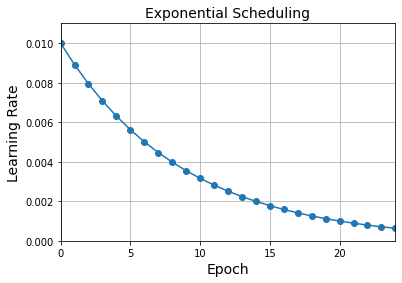

In [72]:
# extra code – this cell plots exponential scheduling

plt.plot(history.epoch, history.history["lr"], "o-")
plt.axis([0, n_epochs - 1, 0, 0.011])
plt.xlabel("Epoch")
plt.ylabel("Learning Rate")
plt.title("Exponential Scheduling", fontsize=14)
plt.grid(True)
plt.show()

The schedule function can take the current learning rate as a second argument:

In [73]:
def exponential_decay_fn(epoch, lr):
    return lr * 0.1 ** (1 / 20)

**Extra material**: if you want to update the learning rate at each iteration rather than at each epoch, you can write your own callback class:

In [74]:
K = tf.keras.backend

class ExponentialDecay(tf.keras.callbacks.Callback):
    def __init__(self, n_steps=40_000):
        super().__init__()
        self.n_steps = n_steps

    def on_batch_begin(self, batch, logs=None):
        # Note: the `batch` argument is reset at each epoch
        lr = K.get_value(self.model.optimizer.learning_rate)
        new_learning_rate = lr * 0.1 ** (1 / self.n_steps)
        K.set_value(self.model.optimizer.learning_rate, new_learning_rate)

    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        logs['lr'] = K.get_value(self.model.optimizer.learning_rate)

In [75]:
lr0 = 0.01
model = build_model()
optimizer = tf.keras.optimizers.legacy.SGD(learning_rate=lr0)
model.compile(loss="sparse_categorical_crossentropy", optimizer=optimizer,
              metrics=["accuracy"])

In [76]:
%%time
n_epochs = 25
batch_size = 32
n_steps = n_epochs * math.ceil(len(X_train) / batch_size)
exp_decay = ExponentialDecay(n_steps)
history = model.fit(X_train, y_train, epochs=n_epochs,
                    validation_data=(X_valid, y_valid),
                    callbacks=[exp_decay])

Epoch 1/25
1719/1719 [==============================] - 1s 769us/step - loss: 0.6847 - accuracy: 0.7628 - val_loss: 0.4851 - val_accuracy: 0.8318 - lr: 0.0091
Epoch 2/25
1719/1719 [==============================] - 1s 717us/step - loss: 0.4641 - accuracy: 0.8365 - val_loss: 0.4422 - val_accuracy: 0.8360 - lr: 0.0083
Epoch 3/25
1719/1719 [==============================] - 1s 716us/step - loss: 0.4178 - accuracy: 0.8509 - val_loss: 0.4065 - val_accuracy: 0.8520 - lr: 0.0076
Epoch 4/25
1719/1719 [==============================] - 1s 722us/step - loss: 0.3939 - accuracy: 0.8602 - val_loss: 0.3825 - val_accuracy: 0.8616 - lr: 0.0069
Epoch 5/25
1719/1719 [==============================] - 1s 726us/step - loss: 0.3751 - accuracy: 0.8659 - val_loss: 0.3735 - val_accuracy: 0.8622 - lr: 0.0063
Epoch 6/25
1719/1719 [==============================] - 1s 719us/step - loss: 0.3607 - accuracy: 0.8715 - val_loss: 0.3793 - val_accuracy: 0.8638 - lr: 0.0058
Epoch 7/25
1719/1719 [========================

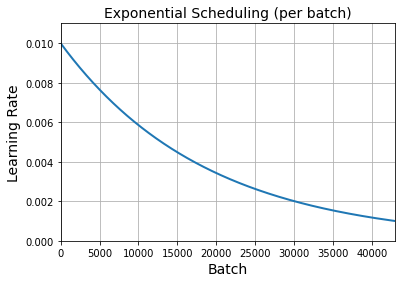

In [77]:
n_steps = n_epochs * math.ceil(len(X_train) / batch_size)
steps = np.arange(n_steps)
decay_rate = 0.1
lrs = lr0 * decay_rate ** (steps / n_steps)

plt.plot(steps, lrs, "-", linewidth=2)
plt.axis([0, n_steps - 1, 0, lr0 * 1.1])
plt.xlabel("Batch")
plt.ylabel("Learning Rate")
plt.title("Exponential Scheduling (per batch)", fontsize=14)
plt.grid(True)
plt.show()

### Piecewise Constant Scheduling

In [78]:
def piecewise_constant_fn(epoch):
    if epoch < 5:
        return 0.01
    elif epoch < 15:
        return 0.005
    else:
        return 0.001

In [79]:
# extra code – this cell demonstrates a more general way to define
#              piecewise constant scheduling.

def piecewise_constant(boundaries, values):
    boundaries = np.array([0] + boundaries)
    values = np.array(values)
    def piecewise_constant_fn(epoch):
        return values[(boundaries > epoch).argmax() - 1]
    return piecewise_constant_fn

piecewise_constant_fn = piecewise_constant([5, 15], [0.01, 0.005, 0.001])

In [80]:
%%time
# extra code – use a tf.keras.callbacks.LearningRateScheduler like earlier

n_epochs = 25

lr_scheduler = tf.keras.callbacks.LearningRateScheduler(piecewise_constant_fn)

model = build_model()
optimizer = tf.keras.optimizers.legacy.Nadam(learning_rate=lr0)
model.compile(loss="sparse_categorical_crossentropy", optimizer=optimizer,
              metrics=["accuracy"])
history = model.fit(X_train, y_train, epochs=n_epochs,
                    validation_data=(X_valid, y_valid),
                    callbacks=[lr_scheduler])

Epoch 1/25
1719/1719 [==============================] - 2s 1ms/step - loss: 0.5844 - accuracy: 0.7918 - val_loss: 0.5253 - val_accuracy: 0.8082 - lr: 0.0100
Epoch 2/25
1719/1719 [==============================] - 2s 1ms/step - loss: 0.4545 - accuracy: 0.8387 - val_loss: 0.4780 - val_accuracy: 0.8232 - lr: 0.0100
Epoch 3/25
1719/1719 [==============================] - 2s 1ms/step - loss: 0.4217 - accuracy: 0.8516 - val_loss: 0.4579 - val_accuracy: 0.8438 - lr: 0.0100
Epoch 4/25
1719/1719 [==============================] - 2s 1ms/step - loss: 0.4139 - accuracy: 0.8558 - val_loss: 0.4159 - val_accuracy: 0.8550 - lr: 0.0100
Epoch 5/25
1719/1719 [==============================] - 2s 1ms/step - loss: 0.4017 - accuracy: 0.8602 - val_loss: 0.4339 - val_accuracy: 0.8504 - lr: 0.0100
Epoch 6/25
1719/1719 [==============================] - 2s 1ms/step - loss: 0.3498 - accuracy: 0.8749 - val_loss: 0.3911 - val_accuracy: 0.8610 - lr: 0.0050
Epoch 7/25
1719/1719 [==============================] - 2s

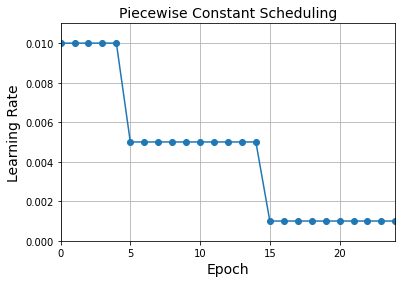

In [81]:
# extra code – this cell plots piecewise constant scheduling

plt.plot(history.epoch, history.history["lr"], "o-")
plt.axis([0, n_epochs - 1, 0, 0.011])
plt.xlabel("Epoch")
plt.ylabel("Learning Rate")
plt.title("Piecewise Constant Scheduling", fontsize=14)
plt.grid(True)
plt.show()

### Performance Scheduling

- Run the early stopping checks
- But reduce the learning rate instead of stopping

In [82]:
# extra code – build and compile the model

model = build_model()
optimizer = tf.keras.optimizers.SGD(learning_rate=lr0)
model.compile(loss="sparse_categorical_crossentropy", optimizer=optimizer,
              metrics=["accuracy"])

In [83]:
%%time
lr_scheduler = tf.keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=5)
history = model.fit(X_train, y_train, epochs=n_epochs,
                    validation_data=(X_valid, y_valid),
                    callbacks=[lr_scheduler])

Epoch 1/25
1719/1719 [==============================] - 1s 676us/step - loss: 0.6797 - accuracy: 0.7629 - val_loss: 0.4808 - val_accuracy: 0.8330 - lr: 0.0100
Epoch 2/25
1719/1719 [==============================] - 1s 630us/step - loss: 0.4664 - accuracy: 0.8359 - val_loss: 0.4454 - val_accuracy: 0.8356 - lr: 0.0100
Epoch 3/25
1719/1719 [==============================] - 1s 628us/step - loss: 0.4175 - accuracy: 0.8511 - val_loss: 0.4160 - val_accuracy: 0.8558 - lr: 0.0100
Epoch 4/25
1719/1719 [==============================] - 1s 627us/step - loss: 0.3930 - accuracy: 0.8614 - val_loss: 0.3845 - val_accuracy: 0.8660 - lr: 0.0100
Epoch 5/25
1719/1719 [==============================] - 1s 629us/step - loss: 0.3721 - accuracy: 0.8683 - val_loss: 0.3786 - val_accuracy: 0.8628 - lr: 0.0100
Epoch 6/25
1719/1719 [==============================] - 1s 628us/step - loss: 0.3559 - accuracy: 0.8729 - val_loss: 0.3749 - val_accuracy: 0.8658 - lr: 0.0100
Epoch 7/25
1719/1719 [========================

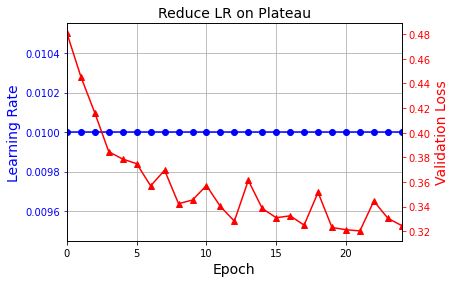

In [84]:
# extra code – this cell plots performance scheduling

plt.plot(history.epoch, history.history["lr"], "bo-")
plt.xlabel("Epoch")
plt.ylabel("Learning Rate", color='b')
plt.tick_params('y', colors='b')
plt.gca().set_xlim(0, n_epochs - 1)
plt.grid(True)

ax2 = plt.gca().twinx()
ax2.plot(history.epoch, history.history["val_loss"], "r^-")
ax2.set_ylabel('Validation Loss', color='r')
ax2.tick_params('y', colors='r')

plt.title("Reduce LR on Plateau", fontsize=14)
plt.show()

### tf.keras schedulers

In [85]:
import math

batch_size = 32
n_epochs = 25
n_steps = n_epochs * math.ceil(len(X_train) / batch_size)
scheduled_learning_rate = tf.keras.optimizers.schedules.ExponentialDecay(
    initial_learning_rate=0.01, decay_steps=n_steps, decay_rate=0.1)
optimizer = tf.keras.optimizers.SGD(learning_rate=scheduled_learning_rate)

In [86]:
%%time
# extra code – build and train the model
model = build_and_train_model(optimizer)

Epoch 1/10
1719/1719 [==============================] - 1s 727us/step - loss: 0.7151 - accuracy: 0.7532 - val_loss: 0.5126 - val_accuracy: 0.8224
Epoch 2/10
1719/1719 [==============================] - 1s 692us/step - loss: 0.4804 - accuracy: 0.8300 - val_loss: 0.4576 - val_accuracy: 0.8338
Epoch 3/10
1719/1719 [==============================] - 1s 687us/step - loss: 0.4297 - accuracy: 0.8479 - val_loss: 0.4254 - val_accuracy: 0.8520
Epoch 4/10
1719/1719 [==============================] - 1s 681us/step - loss: 0.4036 - accuracy: 0.8581 - val_loss: 0.4042 - val_accuracy: 0.8588
Epoch 5/10
1719/1719 [==============================] - 1s 682us/step - loss: 0.3831 - accuracy: 0.8646 - val_loss: 0.3907 - val_accuracy: 0.8606
Epoch 6/10
1719/1719 [==============================] - 1s 686us/step - loss: 0.3675 - accuracy: 0.8697 - val_loss: 0.3976 - val_accuracy: 0.8594
Epoch 7/10
1719/1719 [==============================] - 1s 688us/step - loss: 0.3559 - accuracy: 0.8729 - val_loss: 0.3763 -

For piecewise constant scheduling, try this:

In [87]:
# extra code – shows how to use PiecewiseConstantDecay
scheduled_learning_rate = tf.keras.optimizers.schedules.PiecewiseConstantDecay(
    boundaries=[5. * n_steps_per_epoch, 15. * n_steps_per_epoch],
    values=[0.01, 0.005, 0.001])

### 1Cycle scheduling

- Strategy 2
- Start low, then increase, then reduce

The `ExponentialLearningRate` custom callback updates the learning rate during training, at the end of each batch. It multiplies it by a constant `factor`. It also saves the learning rate and loss at each batch. Since `logs["loss"]` is actually the mean loss since the start of the epoch, and we want to save the batch loss instead, we must compute the mean times the number of batches since the beginning of the epoch to get the total loss so far, then we subtract the total loss at the previous batch to get the current batch's loss.

In [88]:
K = tf.keras.backend

class ExponentialLearningRate(tf.keras.callbacks.Callback):
    def __init__(self, factor):
        self.factor = factor
        self.rates = []
        self.losses = []

    def on_epoch_begin(self, epoch, logs=None):
        self.sum_of_epoch_losses = 0

    def on_batch_end(self, batch, logs=None):
        mean_epoch_loss = logs["loss"]  # the epoch's mean loss so far 
        new_sum_of_epoch_losses = mean_epoch_loss * (batch + 1)
        batch_loss = new_sum_of_epoch_losses - self.sum_of_epoch_losses
        self.sum_of_epoch_losses = new_sum_of_epoch_losses
        self.rates.append(K.get_value(self.model.optimizer.learning_rate))
        self.losses.append(batch_loss)
        K.set_value(self.model.optimizer.learning_rate,
                    self.model.optimizer.learning_rate * self.factor)

The `find_learning_rate()` function trains the model using the `ExponentialLearningRate` callback, and it returns the learning rates and corresponding batch losses. At the end, it restores the model and its optimizer to their initial state.

In [89]:
def find_learning_rate(model, X, y, epochs=1, batch_size=32, min_rate=1e-4,
                       max_rate=1):
    init_weights = model.get_weights()
    iterations = math.ceil(len(X) / batch_size) * epochs
    factor = (max_rate / min_rate) ** (1 / iterations)
    init_lr = K.get_value(model.optimizer.learning_rate)
    K.set_value(model.optimizer.learning_rate, min_rate)
    exp_lr = ExponentialLearningRate(factor)
    history = model.fit(X, y, epochs=epochs, batch_size=batch_size,
                        callbacks=[exp_lr])
    K.set_value(model.optimizer.learning_rate, init_lr)
    model.set_weights(init_weights)
    return exp_lr.rates, exp_lr.losses

The `plot_lr_vs_loss()` function plots the learning rates vs the losses. The optimal learning rate to use as the maximum learning rate in 1cycle is near the bottom of the curve.

In [90]:
def plot_lr_vs_loss(rates, losses):
    plt.plot(rates, losses, "b")
    plt.gca().set_xscale('log')
    max_loss = losses[0] + min(losses)
    plt.hlines(min(losses), min(rates), max(rates), color="k")
    plt.axis([min(rates), max(rates), 0, max_loss])
    plt.xlabel("Learning rate")
    plt.ylabel("Loss")
    plt.grid()

Let's build a simple Fashion MNIST model and compile it:

In [91]:
model = build_model()
model.compile(loss="sparse_categorical_crossentropy",
              optimizer=tf.keras.optimizers.SGD(learning_rate=0.001),
              metrics=["accuracy"])

Now let's find the optimal max learning rate for 1cycle:

430/430 [==============================] - 1s 1ms/step - loss: 1.7882 - accuracy: 0.3965


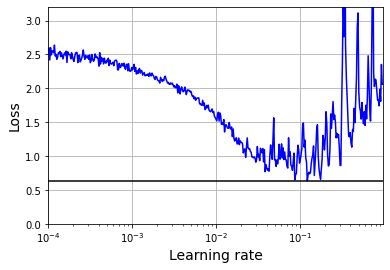

In [92]:
batch_size = 128
rates, losses = find_learning_rate(model, X_train, y_train, epochs=1,
                                   batch_size=batch_size)
plot_lr_vs_loss(rates, losses)

Looks like the max learning rate to use for 1cycle is around 10<sup>–1</sup>.

The `OneCycleScheduler` custom callback updates the learning rate at the beginning of each batch. It applies the logic described in the book: increase the learning rate linearly during about half of training, then reduce it linearly back to the initial learning rate, and lastly reduce it down to close to zero linearly for the very last part of training.

In [93]:
class OneCycleScheduler(tf.keras.callbacks.Callback):
    def __init__(self, iterations, max_lr=1e-3, start_lr=None,
                 last_iterations=None, last_lr=None):
        self.iterations = iterations
        self.max_lr = max_lr
        self.start_lr = start_lr or max_lr / 10
        self.last_iterations = last_iterations or iterations // 10 + 1
        self.half_iteration = (iterations - self.last_iterations) // 2
        self.last_lr = last_lr or self.start_lr / 1000
        self.iteration = 0

    def _interpolate(self, iter1, iter2, lr1, lr2):
        return (lr2 - lr1) * (self.iteration - iter1) / (iter2 - iter1) + lr1

    def on_batch_begin(self, batch, logs):
        if self.iteration < self.half_iteration:
            lr = self._interpolate(0, self.half_iteration, self.start_lr,
                                   self.max_lr)
        elif self.iteration < 2 * self.half_iteration:
            lr = self._interpolate(self.half_iteration, 2 * self.half_iteration,
                                   self.max_lr, self.start_lr)
        else:
            lr = self._interpolate(2 * self.half_iteration, self.iterations,
                                   self.start_lr, self.last_lr)
        self.iteration += 1
        K.set_value(self.model.optimizer.learning_rate, lr)

Let's build and compile a simple Fashion MNIST model, then train it using the `OneCycleScheduler` callback:

In [94]:
%%time
model = build_model()
model.compile(loss="sparse_categorical_crossentropy",
              optimizer=tf.keras.optimizers.SGD(),
              metrics=["accuracy"])
n_epochs = 25
onecycle = OneCycleScheduler(math.ceil(len(X_train) / batch_size) * n_epochs,
                             max_lr=0.1)
history = model.fit(X_train, y_train, epochs=n_epochs, batch_size=batch_size,
                    validation_data=(X_valid, y_valid),
                    callbacks=[onecycle])

Epoch 1/25
430/430 [==============================] - 1s 1ms/step - loss: 0.9903 - accuracy: 0.6762 - val_loss: 0.6188 - val_accuracy: 0.7832
Epoch 2/25
430/430 [==============================] - 0s 1ms/step - loss: 0.5907 - accuracy: 0.7916 - val_loss: 0.5037 - val_accuracy: 0.8228
Epoch 3/25
430/430 [==============================] - 0s 1ms/step - loss: 0.5076 - accuracy: 0.8211 - val_loss: 0.4657 - val_accuracy: 0.8334
Epoch 4/25
430/430 [==============================] - 0s 1ms/step - loss: 0.4597 - accuracy: 0.8364 - val_loss: 0.4322 - val_accuracy: 0.8436
Epoch 5/25
430/430 [==============================] - 0s 1ms/step - loss: 0.4302 - accuracy: 0.8458 - val_loss: 0.4224 - val_accuracy: 0.8398
Epoch 6/25
430/430 [==============================] - 0s 1ms/step - loss: 0.4015 - accuracy: 0.8553 - val_loss: 0.5160 - val_accuracy: 0.8048
Epoch 7/25
430/430 [==============================] - 0s 1ms/step - loss: 0.3869 - accuracy: 0.8613 - val_loss: 0.3944 - val_accuracy: 0.8556
Epoch 

# Avoiding Overfitting Through Regularization

- Recall that **regularisation** is any process for avoiding both over- and underfit
    - Cross validation is one example
    - Early stopping was introduced in the last topic
- Deep learning models have huge flexibility in finding weights to make predictions
    - **Pro**: we can fit a huge variety of datasets
    - **Con**: it is very easy to predict the training set almost perfectly, but than have poor generalisation error
- We saw that SGD regression could use modified loss functions that help avoid overfitting
    - the same process can be applied in NN

## $\ell_1$ and $\ell_2$ regularization

In [95]:
layer = tf.keras.layers.Dense(100, activation="relu",
                              kernel_initializer="he_normal",
                              kernel_regularizer=tf.keras.regularizers.l2(0.01))

Or use `l1(0.1)` for ℓ<sub>1</sub> regularization with a factor of 0.1, or `l1_l2(0.1, 0.01)` for both ℓ<sub>1</sub> and ℓ<sub>2</sub> regularization, with factors 0.1 and 0.01 respectively.

In [96]:
tf.random.set_seed(42)  # extra code – for reproducibility

In [97]:
from functools import partial

RegularizedDense = partial(tf.keras.layers.Dense,
                           activation="relu",
                           kernel_initializer="he_normal",
                           kernel_regularizer=tf.keras.regularizers.l2(0.01))

model = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=[28, 28]),
    RegularizedDense(100),
    RegularizedDense(100),
    RegularizedDense(10, activation="softmax")
])

In [98]:
# extra code – compile and train the model
optimizer = tf.keras.optimizers.SGD(learning_rate=0.02)
model.compile(loss="sparse_categorical_crossentropy", optimizer=optimizer,
              metrics=["accuracy"])
history = model.fit(X_train, y_train, epochs=2,
                    validation_data=(X_valid, y_valid))

Epoch 1/2
1719/1719 [==============================] - 1s 664us/step - loss: 3.0872 - accuracy: 0.7812 - val_loss: 1.8428 - val_accuracy: 0.8266
Epoch 2/2
1719/1719 [==============================] - 1s 628us/step - loss: 1.4181 - accuracy: 0.8161 - val_loss: 1.1268 - val_accuracy: 0.8172


## Dropout

- A very popular regularisation technique
- Many state-of-the-art NNs use dropout
    - gaining maybe 2% accuracy
    - for very little effort
- Strategy:
    - At any learning stage, each hidden layer neuron has a fixed probability of being *dropped*
    - i.e. it will be completely ignored at this step
    - It may or may not be dropped at the next step
- Results:
    - Less sensitivity to small changes in the inputs
    - A more robust NN
    - Less overfit
    - Better generalisation

In [99]:
tf.random.set_seed(42)  # extra code – for reproducibility

In [100]:
model = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=[28, 28]),
    tf.keras.layers.Dropout(rate=0.2),
    tf.keras.layers.Dense(100, activation="relu",
                          kernel_initializer="he_normal"),
    tf.keras.layers.Dropout(rate=0.2),
    tf.keras.layers.Dense(100, activation="relu",
                          kernel_initializer="he_normal"),
    tf.keras.layers.Dropout(rate=0.2),
    tf.keras.layers.Dense(10, activation="softmax")
])

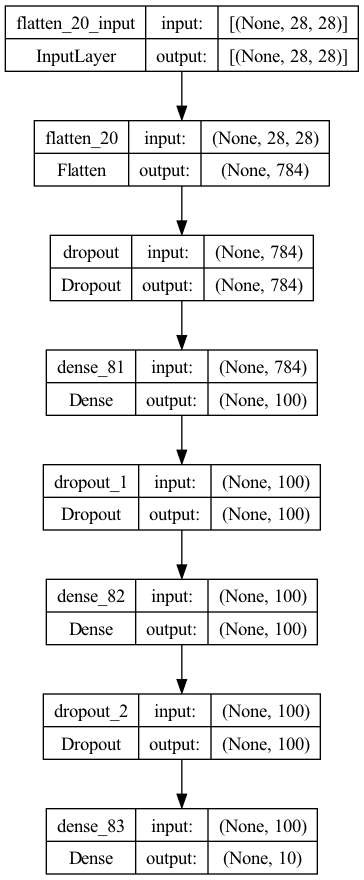

In [101]:
tf.keras.utils.plot_model(model, show_shapes=True)

In [102]:
%%time
# extra code – compile and train the model
optimizer = tf.keras.optimizers.SGD(learning_rate=0.01, momentum=0.9)
model.compile(loss="sparse_categorical_crossentropy", optimizer=optimizer,
              metrics=["accuracy"])
history = model.fit(X_train, y_train, epochs=10,
                    validation_data=(X_valid, y_valid))

Epoch 1/10
1719/1719 [==============================] - 2s 867us/step - loss: 0.6726 - accuracy: 0.7515 - val_loss: 0.4606 - val_accuracy: 0.8234
Epoch 2/10
1719/1719 [==============================] - 1s 825us/step - loss: 0.5082 - accuracy: 0.8151 - val_loss: 0.4158 - val_accuracy: 0.8362
Epoch 3/10
1719/1719 [==============================] - 1s 824us/step - loss: 0.4714 - accuracy: 0.8276 - val_loss: 0.3849 - val_accuracy: 0.8566
Epoch 4/10
1719/1719 [==============================] - 1s 817us/step - loss: 0.4436 - accuracy: 0.8359 - val_loss: 0.3898 - val_accuracy: 0.8550
Epoch 5/10
1719/1719 [==============================] - 1s 823us/step - loss: 0.4311 - accuracy: 0.8404 - val_loss: 0.3749 - val_accuracy: 0.8546
Epoch 6/10
1719/1719 [==============================] - 1s 823us/step - loss: 0.4227 - accuracy: 0.8429 - val_loss: 0.3605 - val_accuracy: 0.8648
Epoch 7/10
1719/1719 [==============================] - 1s 824us/step - loss: 0.4134 - accuracy: 0.8472 - val_loss: 0.3609 -

The training accuracy looks like it's lower than the validation accuracy, but that's just because dropout is only active during training. If we evaluate the model on the training set after training (i.e., with dropout turned off), we get the "real" training accuracy, which is very slightly higher than the validation accuracy and the test accuracy:

In [103]:
model.evaluate(X_train, y_train)

1719/1719 [==============================] - 1s 410us/step - loss: 0.3146 - accuracy: 0.8823


[0.3146004378795624, 0.8823272585868835]

In [104]:
model.evaluate(X_test, y_test)

313/313 [==============================] - 0s 406us/step - loss: 0.3698 - accuracy: 0.8647


[0.36976414918899536, 0.8647000193595886]

**Note**: make sure to use `AlphaDropout` instead of `Dropout` if you want to build a self-normalizing neural net using SELU.

## MC Dropout

- A recent alternative
- Improve's reliability of predictions
    - i.e. less likely to be confident but wrong
- Clearly important for many applications
    - self-driving cars
    - medical diagnostics
- Often a small gain in accuracy
    - together with a good estimate of how confident we are when predicting
    - from the variance of the sampled probabilities
- To see that it works we 
    1. take the dropout model just trained
    2. get 100 slightly different predictions (by setting *training=True* so that different dropouts occur)
    3. average the results

In [105]:
tf.random.set_seed(42)  # extra code – for reproducibility

In [106]:
%%time
y_probas = np.stack([model(X_test, training=True)
                     for sample in range(100)])
y_proba = y_probas.mean(axis=0)

CPU times: user 9.61 s, sys: 2.47 s, total: 12.1 s
Wall time: 2.87 s


In [107]:
model.predict(X_test[:1]).round(3)

1/1 [==============================] - 0s 35ms/step


array([[0.   , 0.   , 0.   , 0.   , 0.   , 0.024, 0.   , 0.162, 0.   ,
        0.813]], dtype=float32)

In [108]:
y_proba[0].round(3)

array([0.   , 0.001, 0.   , 0.001, 0.   , 0.064, 0.   , 0.206, 0.004,
       0.724], dtype=float32)

In [109]:
y_std = y_probas.std(axis=0)
y_std[0].round(3)

array([0.001, 0.001, 0.001, 0.001, 0.001, 0.076, 0.001, 0.169, 0.01 ,
       0.196], dtype=float32)

In [110]:
y_pred = y_proba.argmax(axis=1)
accuracy = (y_pred == y_test).sum() / len(y_test)
accuracy

0.8655

- Monte Carlo Dropout in keras

In [111]:
class MCDropout(tf.keras.layers.Dropout):
    def call(self, inputs, training=None):
        return super().call(inputs, training=True)

In [112]:
# extra code – shows how to convert Dropout to MCDropout in a Sequential model
Dropout = tf.keras.layers.Dropout
mc_model = tf.keras.Sequential([
    MCDropout(layer.rate) if isinstance(layer, Dropout) else layer
    for layer in model.layers
])
mc_model.set_weights(model.get_weights())

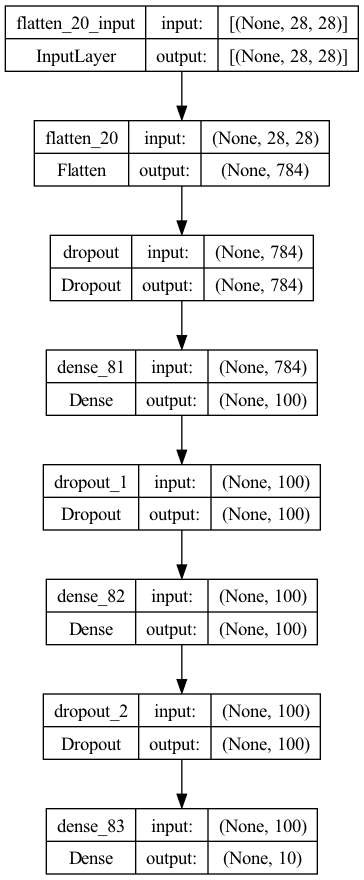

In [113]:
tf.keras.utils.plot_model(model, show_shapes=True)

Now we can use the model with MC Dropout:

In [114]:
# extra code – shows that the model works without retraining
tf.random.set_seed(42)
np.mean([mc_model.predict(X_test[:1])
         for sample in range(100)], axis=0).round(2)

1/1 [==============================] - 0s 7ms/step


array([[0.  , 0.  , 0.  , 0.  , 0.  , 0.07, 0.  , 0.21, 0.01, 0.71]],
      dtype=float32)

## Max norm

- Constrain incoming weights to below a fixed value

In [115]:
dense = tf.keras.layers.Dense(
    100, activation="relu", kernel_initializer="he_normal",
    kernel_constraint=tf.keras.constraints.max_norm(1.))

In [116]:
%%time
# extra code – shows how to apply max norm to every hidden layer in a model

MaxNormDense = partial(tf.keras.layers.Dense,
                       activation="relu", kernel_initializer="he_normal",
                       kernel_constraint=tf.keras.constraints.max_norm(1.))

tf.random.set_seed(42)
model = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=[28, 28]),
    MaxNormDense(100),
    MaxNormDense(100),
    tf.keras.layers.Dense(10, activation="softmax")
])
optimizer = tf.keras.optimizers.SGD(learning_rate=0.01, momentum=0.9)
model.compile(loss="sparse_categorical_crossentropy", optimizer=optimizer,
              metrics=["accuracy"])
history = model.fit(X_train, y_train, epochs=10,
                    validation_data=(X_valid, y_valid))

Epoch 1/10
1719/1719 [==============================] - 2s 781us/step - loss: 0.5490 - accuracy: 0.8037 - val_loss: 0.4625 - val_accuracy: 0.8176
Epoch 2/10
1719/1719 [==============================] - 1s 733us/step - loss: 0.4101 - accuracy: 0.8501 - val_loss: 0.4249 - val_accuracy: 0.8364
Epoch 3/10
1719/1719 [==============================] - 1s 740us/step - loss: 0.3789 - accuracy: 0.8599 - val_loss: 0.3853 - val_accuracy: 0.8614
Epoch 4/10
1719/1719 [==============================] - 1s 733us/step - loss: 0.3593 - accuracy: 0.8679 - val_loss: 0.3574 - val_accuracy: 0.8704
Epoch 5/10
1719/1719 [==============================] - 1s 729us/step - loss: 0.3445 - accuracy: 0.8713 - val_loss: 0.3499 - val_accuracy: 0.8684
Epoch 6/10
1719/1719 [==============================] - 1s 733us/step - loss: 0.3413 - accuracy: 0.8735 - val_loss: 0.4068 - val_accuracy: 0.8568
Epoch 7/10
1719/1719 [==============================] - 1s 743us/step - loss: 0.3281 - accuracy: 0.8772 - val_loss: 0.4030 -

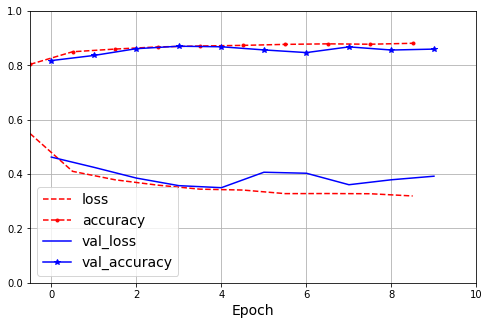

In [117]:
plt.figure(figsize=(8, 5))
for key, style in zip(history.history, ["r--", "r--.", "b-", "b-*"]):
    epochs = np.array(history.epoch) + (0 if key.startswith("val_") else -0.5)
    plt.plot(epochs, history.history[key], style, label=key)
plt.xlabel("Epoch")
plt.axis([-0.5, 10, 0., 1])
plt.legend(loc="lower left")
plt.grid()
plt.show()

# Exercises

## 1. to 7.

1. Glorot initialization and He initialization were designed to make the output standard deviation as close as possible to the input standard deviation, at least at the beginning of training. This reduces the vanishing/exploding gradients problem.
2. No, all weights should be sampled independently; they should not all have the same initial value. One important goal of sampling weights randomly is to break symmetry: if all the weights have the same initial value, even if that value is not zero, then symmetry is not broken (i.e., all neurons in a given layer are equivalent), and backpropagation will be unable to break it. Concretely, this means that all the neurons in any given layer will always have the same weights. It's like having just one neuron per layer, and much slower. It is virtually impossible for such a configuration to converge to a good solution.
3. It is perfectly fine to initialize the bias terms to zero. Some people like to initialize them just like weights, and that's OK too; it does not make much difference.
4. ReLU is usually a good default for the hidden layers, as it is fast and yields good results. Its ability to output precisely zero can also be useful in some cases (e.g., see Chapter 17). Moreover, it can sometimes benefit from optimized implementations as well as from hardware acceleration. The leaky ReLU variants of ReLU can improve the model's quality without hindering its speed too much compared to ReLU. For large neural nets and more complex problems, GLU, Swish and Mish can give you a slightly higher quality model, but they have a computational cost. The hyperbolic tangent (tanh) can be useful in the output layer if you need to output a number in a fixed range (by default between –1 and 1), but nowadays it is not used much in hidden layers, except in recurrent nets. The sigmoid activation function is also useful in the output layer when you need to estimate a probability (e.g., for binary classification), but it is rarely used in hidden layers (there are exceptions—for example, for the coding layer of variational autoencoders; see Chapter 17). The softplus activation function is useful in the output layer when you need to ensure that the output will always be positive. The softmax activation function is useful in the output layer to estimate probabilities for mutually exclusive classes, but it is rarely (if ever) used in hidden layers.
5. If you set the `momentum` hyperparameter too close to 1 (e.g., 0.99999) when using an `SGD` optimizer, then the algorithm will likely pick up a lot of speed, hopefully moving roughly toward the global minimum, but its momentum will carry it right past the minimum. Then it will slow down and come back, accelerate again, overshoot again, and so on. It may oscillate this way many times before converging, so overall it will take much longer to converge than with a smaller `momentum` value.
6. One way to produce a sparse model (i.e., with most weights equal to zero) is to train the model normally, then zero out tiny weights. For more sparsity, you can apply ℓ<sub>1</sub> regularization during training, which pushes the optimizer toward sparsity. A third option is to use the TensorFlow Model Optimization Toolkit.
7. Yes, dropout does slow down training, in general roughly by a factor of two. However, it has no impact on inference speed since it is only turned on during training. MC Dropout is exactly like dropout during training, but it is still active during inference, so each inference is slowed down slightly. More importantly, when using MC Dropout you generally want to run inference 10 times or more to get better predictions. This means that making predictions is slowed down by a factor of 10 or more.

## 8. Deep Learning on CIFAR10

### a.
*Exercise: Build a DNN with 20 hidden layers of 100 neurons each (that's too many, but it's the point of this exercise). Use He initialization and the Swish activation function.*

In [118]:
tf.random.set_seed(42)

model = tf.keras.Sequential()
model.add(tf.keras.layers.Flatten(input_shape=[32, 32, 3]))
for _ in range(20):
    model.add(tf.keras.layers.Dense(100,
                                    activation="swish",
                                    kernel_initializer="he_normal"))

### b.
*Exercise: Using Nadam optimization and early stopping, train the network on the CIFAR10 dataset. You can load it with `tf.keras.datasets.cifar10.load_data()`. The dataset is composed of 60,000 32 × 32–pixel color images (50,000 for training, 10,000 for testing) with 10 classes, so you'll need a softmax output layer with 10 neurons. Remember to search for the right learning rate each time you change the model's architecture or hyperparameters.*

Let's add the output layer to the model:

In [119]:
model.add(tf.keras.layers.Dense(10, activation="softmax"))

Let's use a Nadam optimizer with a learning rate of 5e-5. I tried learning rates 1e-5, 3e-5, 1e-4, 3e-4, 1e-3, 3e-3 and 1e-2, and I compared their learning curves for 10 epochs each (using the TensorBoard callback, below). The learning rates 3e-5 and 1e-4 were pretty good, so I tried 5e-5, which turned out to be slightly better.

In [120]:
optimizer = tf.keras.optimizers.Nadam(learning_rate=5e-5)
model.compile(loss="sparse_categorical_crossentropy",
              optimizer=optimizer,
              metrics=["accuracy"])

Let's load the CIFAR10 dataset. We also want to use early stopping, so we need a validation set. Let's use the first 5,000 images of the original training set as the validation set:

In [121]:
cifar10 = tf.keras.datasets.cifar10.load_data()
(X_train_full, y_train_full), (X_test, y_test) = cifar10

X_train = X_train_full[5000:]
y_train = y_train_full[5000:]
X_valid = X_train_full[:5000]
y_valid = y_train_full[:5000]

170498071/170498071 [==============================] - 94s 1us/step


Now we can create the callbacks we need and train the model:

In [122]:
early_stopping_cb = tf.keras.callbacks.EarlyStopping(patience=20,
                                                     restore_best_weights=True)
model_checkpoint_cb = tf.keras.callbacks.ModelCheckpoint("my_cifar10_model",
                                                         save_best_only=True)
run_index = 1 # increment every time you train the model
run_logdir = Path() / "my_cifar10_logs" / f"run_{run_index:03d}"
tensorboard_cb = tf.keras.callbacks.TensorBoard(run_logdir)
callbacks = [early_stopping_cb, model_checkpoint_cb, tensorboard_cb]

In [123]:
%load_ext tensorboard
%tensorboard --logdir=./my_cifar10_logs

In [124]:
model.fit(X_train, y_train, epochs=100,
          validation_data=(X_valid, y_valid),
          callbacks=callbacks)

Epoch 1/100
1406/1407 [============================>.] - ETA: 0s - loss: 5.9997 - accuracy: 0.1467INFO:tensorflow:Assets written to: my_cifar10_model/assets


INFO:tensorflow:Assets written to: my_cifar10_model/assets


1407/1407 [==============================] - 9s 6ms/step - loss: 5.9990 - accuracy: 0.1468 - val_loss: 2.1372 - val_accuracy: 0.2084
Epoch 2/100
1405/1407 [============================>.] - ETA: 0s - loss: 2.0741 - accuracy: 0.2281INFO:tensorflow:Assets written to: my_cifar10_model/assets


INFO:tensorflow:Assets written to: my_cifar10_model/assets


1407/1407 [==============================] - 8s 5ms/step - loss: 2.0741 - accuracy: 0.2282 - val_loss: 2.0335 - val_accuracy: 0.2204
Epoch 3/100
1403/1407 [============================>.] - ETA: 0s - loss: 1.9642 - accuracy: 0.2744INFO:tensorflow:Assets written to: my_cifar10_model/assets


INFO:tensorflow:Assets written to: my_cifar10_model/assets


... (33 outputs left out)

INFO:tensorflow:Assets written to: my_cifar10_model/assets


1407/1407 [==============================] - 11s 8ms/step - loss: 1.2820 - accuracy: 0.5387 - val_loss: 1.5105 - val_accuracy: 0.4718
Epoch 43/100
1407/1407 [==============================] - 9s 7ms/step - loss: 1.2756 - accuracy: 0.5435 - val_loss: 1.6137 - val_accuracy: 0.4524
Epoch 44/100
1407/1407 [==============================] - 10s 7ms/step - loss: 1.2691 - accuracy: 0.5450 - val_loss: 1.5731 - val_accuracy: 0.4574
Epoch 45/100
1407/1407 [==============================] - 10s 7ms/step - loss: 1.2614 - accuracy: 0.5482 - val_loss: 1.5570 - val_accuracy: 0.4682
Epoch 46/100
1407/1407 [==============================] - 10s 7ms/step - loss: 1.2566 - accuracy: 0.5491 - val_loss: 1.5472 - val_accuracy: 0.4756
Epoch 47/100
1407/1407 [==============================] - 9s 7ms/step - loss: 1.2475 - accuracy: 0.5534 - val_loss: 1.5260 - val_accuracy: 0.4780
Epoch 48/100
1407/1407 [==============================] - 9s 6ms/step - loss: 1.2400 - accuracy: 0.5566 - val_loss: 1.5439 - val_accu

INFO:tensorflow:Assets written to: my_cifar10_model/assets


1407/1407 [==============================] - 10s 7ms/step - loss: 1.2093 - accuracy: 0.5668 - val_loss: 1.5101 - val_accuracy: 0.4764
Epoch 54/100
1407/1407 [==============================] - 10s 7ms/step - loss: 1.2053 - accuracy: 0.5698 - val_loss: 1.5591 - val_accuracy: 0.4670
Epoch 55/100
1407/1407 [==============================] - 9s 7ms/step - loss: 1.1988 - accuracy: 0.5701 - val_loss: 1.5318 - val_accuracy: 0.4800
Epoch 56/100
1407/1407 [==============================] - 10s 7ms/step - loss: 1.1920 - accuracy: 0.5734 - val_loss: 1.5280 - val_accuracy: 0.4776
Epoch 57/100
1407/1407 [==============================] - 9s 7ms/step - loss: 1.1836 - accuracy: 0.5769 - val_loss: 1.5625 - val_accuracy: 0.4652
Epoch 58/100
1407/1407 [==============================] - 9s 6ms/step - loss: 1.1827 - accuracy: 0.5774 - val_loss: 1.5212 - val_accuracy: 0.4816
Epoch 59/100
1407/1407 [==============================] - 9s 7ms/step - loss: 1.1738 - accuracy: 0.5799 - val_loss: 1.5493 - val_accur

In [125]:
model.evaluate(X_valid, y_valid)

157/157 [==============================] - 0s 989us/step - loss: 1.5101 - accuracy: 0.4764


[1.510148048400879, 0.4763999879360199]

The model with the lowest validation loss gets about 46.8% accuracy on the validation set. It took 29 epochs to reach the lowest validation loss, with roughly 10 seconds per epoch on my laptop (without a GPU). Let's see if we can improve the model using Batch Normalization.

### c.
*Exercise: Now try adding Batch Normalization and compare the learning curves: Is it converging faster than before? Does it produce a better model? How does it affect training speed?*

The code below is very similar to the code above, with a few changes:

* I added a BN layer after every Dense layer (before the activation function), except for the output layer.
* I changed the learning rate to 5e-4. I experimented with 1e-5, 3e-5, 5e-5, 1e-4, 3e-4, 5e-4, 1e-3 and 3e-3, and I chose the one with the best validation performance after 20 epochs.
* I renamed the run directories to run_bn_* and the model file name to `my_cifar10_bn_model`.

In [126]:
tf.random.set_seed(42)

model = tf.keras.Sequential()
model.add(tf.keras.layers.Flatten(input_shape=[32, 32, 3]))
for _ in range(20):
    model.add(tf.keras.layers.Dense(100, kernel_initializer="he_normal"))
    model.add(tf.keras.layers.BatchNormalization())
    model.add(tf.keras.layers.Activation("swish"))

model.add(tf.keras.layers.Dense(10, activation="softmax"))

optimizer = tf.keras.optimizers.Nadam(learning_rate=5e-4)
model.compile(loss="sparse_categorical_crossentropy",
              optimizer=optimizer,
              metrics=["accuracy"])

early_stopping_cb = tf.keras.callbacks.EarlyStopping(patience=20,
                                                     restore_best_weights=True)
model_checkpoint_cb = tf.keras.callbacks.ModelCheckpoint("my_cifar10_bn_model",
                                                         save_best_only=True)
run_index = 1 # increment every time you train the model
run_logdir = Path() / "my_cifar10_logs" / f"run_bn_{run_index:03d}"
tensorboard_cb = tf.keras.callbacks.TensorBoard(run_logdir)
callbacks = [early_stopping_cb, model_checkpoint_cb, tensorboard_cb]

model.fit(X_train, y_train, epochs=100,
          validation_data=(X_valid, y_valid),
          callbacks=callbacks)

model.evaluate(X_valid, y_valid)

Epoch 1/100
1403/1407 [============================>.] - ETA: 0s - loss: 2.0512 - accuracy: 0.2493INFO:tensorflow:Assets written to: my_cifar10_bn_model/assets


INFO:tensorflow:Assets written to: my_cifar10_bn_model/assets


1407/1407 [==============================] - 16s 9ms/step - loss: 2.0508 - accuracy: 0.2494 - val_loss: 2.1336 - val_accuracy: 0.2484
Epoch 2/100
1404/1407 [============================>.] - ETA: 0s - loss: 1.7775 - accuracy: 0.3630INFO:tensorflow:Assets written to: my_cifar10_bn_model/assets


INFO:tensorflow:Assets written to: my_cifar10_bn_model/assets


1407/1407 [==============================] - 13s 9ms/step - loss: 1.7775 - accuracy: 0.3630 - val_loss: 1.8479 - val_accuracy: 0.3268
Epoch 3/100
1403/1407 [============================>.] - ETA: 0s - loss: 1.6751 - accuracy: 0.4041INFO:tensorflow:Assets written to: my_cifar10_bn_model/assets


INFO:tensorflow:Assets written to: my_cifar10_bn_model/assets


... (12 outputs left out)

1407/1407 [==============================] - 13s 9ms/step - loss: 1.3281 - accuracy: 0.5309 - val_loss: 1.4805 - val_accuracy: 0.4968
Epoch 12/100
1407/1407 [==============================] - 10s 7ms/step - loss: 1.2990 - accuracy: 0.5441 - val_loss: 1.6032 - val_accuracy: 0.4446
Epoch 13/100
1407/1407 [==============================] - 10s 7ms/step - loss: 1.2743 - accuracy: 0.5508 - val_loss: 1.4908 - val_accuracy: 0.4764
Epoch 14/100
1406/1407 [============================>.] - ETA: 0s - loss: 1.2490 - accuracy: 0.5576INFO:tensorflow:Assets written to: my_cifar10_bn_model/assets


INFO:tensorflow:Assets written to: my_cifar10_bn_model/assets


1407/1407 [==============================] - 13s 9ms/step - loss: 1.2490 - accuracy: 0.5576 - val_loss: 1.4311 - val_accuracy: 0.4980
Epoch 15/100
1407/1407 [==============================] - 10s 7ms/step - loss: 1.2248 - accuracy: 0.5681 - val_loss: 1.6860 - val_accuracy: 0.4534
Epoch 16/100
1407/1407 [==============================] - 10s 7ms/step - loss: 1.2102 - accuracy: 0.5762 - val_loss: 1.5085 - val_accuracy: 0.4762
Epoch 17/100
1407/1407 [==============================] - 10s 7ms/step - loss: 1.1927 - accuracy: 0.5790 - val_loss: 1.6586 - val_accuracy: 0.4368
Epoch 18/100
1407/1407 [==============================] - 10s 7ms/step - loss: 1.1674 - accuracy: 0.5906 - val_loss: 1.4982 - val_accuracy: 0.4752
Epoch 19/100
1407/1407 [==============================] - 10s 7ms/step - loss: 1.1516 - accuracy: 0.5941 - val_loss: 1.5035 - val_accuracy: 0.4724
Epoch 20/100
1407/1407 [==============================] - 10s 7ms/step - loss: 1.1330 - accuracy: 0.6038 - val_loss: 1.4906 - val_a

[1.431058645248413, 0.49799999594688416]

* *Is the model converging faster than before?* Much faster! The previous model took 29 epochs to reach the lowest validation loss, while the new model achieved that same loss in just 12 epochs and continued to make progress until the 17th epoch. The BN layers stabilized training and allowed us to use a much larger learning rate, so convergence was faster.
* *Does BN produce a better model?* Yes! The final model is also much better, with 50.7% validation accuracy instead of 46.7%. It's still not a very good model, but at least it's much better than before (a Convolutional Neural Network would do much better, but that's a different topic, see chapter 14).
* *How does BN affect training speed?* Although the model converged much faster, each epoch took about 15s instead of 10s, because of the extra computations required by the BN layers. But overall the training time (wall time) to reach the best model was shortened by about 10%.

### d.
*Exercise: Try replacing Batch Normalization with SELU, and make the necessary adjustements to ensure the network self-normalizes (i.e., standardize the input features, use LeCun normal initialization, make sure the DNN contains only a sequence of dense layers, etc.).*

In [127]:
tf.random.set_seed(42)

model = tf.keras.Sequential()
model.add(tf.keras.layers.Flatten(input_shape=[32, 32, 3]))
for _ in range(20):
    model.add(tf.keras.layers.Dense(100,
                                    kernel_initializer="lecun_normal",
                                    activation="selu"))

model.add(tf.keras.layers.Dense(10, activation="softmax"))

optimizer = tf.keras.optimizers.Nadam(learning_rate=7e-4)
model.compile(loss="sparse_categorical_crossentropy",
              optimizer=optimizer,
              metrics=["accuracy"])

early_stopping_cb = tf.keras.callbacks.EarlyStopping(
    patience=20, restore_best_weights=True)
model_checkpoint_cb = tf.keras.callbacks.ModelCheckpoint(
    "my_cifar10_selu_model", save_best_only=True)
run_index = 1 # increment every time you train the model
run_logdir = Path() / "my_cifar10_logs" / f"run_selu_{run_index:03d}"
tensorboard_cb = tf.keras.callbacks.TensorBoard(run_logdir)
callbacks = [early_stopping_cb, model_checkpoint_cb, tensorboard_cb]

X_means = X_train.mean(axis=0)
X_stds = X_train.std(axis=0)
X_train_scaled = (X_train - X_means) / X_stds
X_valid_scaled = (X_valid - X_means) / X_stds
X_test_scaled = (X_test - X_means) / X_stds

model.fit(X_train_scaled, y_train, epochs=100,
          validation_data=(X_valid_scaled, y_valid),
          callbacks=callbacks)

model.evaluate(X_valid_scaled, y_valid)

Epoch 1/100
1407/1407 [==============================] - ETA: 0s - loss: 1.9453 - accuracy: 0.2989INFO:tensorflow:Assets written to: my_cifar10_selu_model/assets


INFO:tensorflow:Assets written to: my_cifar10_selu_model/assets


1407/1407 [==============================] - 9s 6ms/step - loss: 1.9453 - accuracy: 0.2989 - val_loss: 1.8716 - val_accuracy: 0.3296
Epoch 2/100
1407/1407 [==============================] - ETA: 0s - loss: 1.7134 - accuracy: 0.3909INFO:tensorflow:Assets written to: my_cifar10_selu_model/assets


INFO:tensorflow:Assets written to: my_cifar10_selu_model/assets


1407/1407 [==============================] - 8s 6ms/step - loss: 1.7134 - accuracy: 0.3909 - val_loss: 1.7325 - val_accuracy: 0.3656
Epoch 3/100
1404/1407 [============================>.] - ETA: 0s - loss: 1.6182 - accuracy: 0.4306INFO:tensorflow:Assets written to: my_cifar10_selu_model/assets


INFO:tensorflow:Assets written to: my_cifar10_selu_model/assets


... (8 outputs left out)

1407/1407 [==============================] - 8s 6ms/step - loss: 1.3301 - accuracy: 0.5392 - val_loss: 1.4761 - val_accuracy: 0.4770
Epoch 10/100
1407/1407 [==============================] - 1052s 748ms/step - loss: 1.2963 - accuracy: 0.5527 - val_loss: 1.5044 - val_accuracy: 0.4866
Epoch 11/100
1407/1407 [==============================] - 7s 5ms/step - loss: 1.2713 - accuracy: 0.5600 - val_loss: 1.5016 - val_accuracy: 0.4934
Epoch 12/100
1407/1407 [==============================] - 7s 5ms/step - loss: 1.2414 - accuracy: 0.5702 - val_loss: 1.4863 - val_accuracy: 0.4964
Epoch 13/100
1407/1407 [==============================] - 7s 5ms/step - loss: 1.2149 - accuracy: 0.5836 - val_loss: 1.4800 - val_accuracy: 0.4994
Epoch 14/100
1407/1407 [==============================] - 7s 5ms/step - loss: 1.1912 - accuracy: 0.5892 - val_loss: 1.4812 - val_accuracy: 0.5004
Epoch 15/100
1407/1407 [==============================] - 7s 5ms/step - loss: 1.1660 - accuracy: 0.5972 - val_loss: 1.4962 - val_acc

INFO:tensorflow:Assets written to: my_cifar10_selu_model/assets


1407/1407 [==============================] - 8s 6ms/step - loss: 1.1272 - accuracy: 0.6159 - val_loss: 1.4761 - val_accuracy: 0.5124
Epoch 18/100
1407/1407 [==============================] - 7s 5ms/step - loss: 1.0975 - accuracy: 0.6253 - val_loss: 1.5022 - val_accuracy: 0.5072
Epoch 19/100
1407/1407 [==============================] - 7s 5ms/step - loss: 1.0832 - accuracy: 0.6297 - val_loss: 1.5873 - val_accuracy: 0.5030
Epoch 20/100
1407/1407 [==============================] - 7s 5ms/step - loss: 1.0547 - accuracy: 0.6393 - val_loss: 1.5111 - val_accuracy: 0.5012
Epoch 21/100
1407/1407 [==============================] - 7s 5ms/step - loss: 1.0422 - accuracy: 0.6444 - val_loss: 1.5483 - val_accuracy: 0.4988
Epoch 22/100
1407/1407 [==============================] - 7s 5ms/step - loss: 1.0264 - accuracy: 0.6503 - val_loss: 1.5877 - val_accuracy: 0.5076
Epoch 23/100
1407/1407 [==============================] - 7s 5ms/step - loss: 1.0053 - accuracy: 0.6574 - val_loss: 1.5950 - val_accuracy

[1.4760777950286865, 0.5123999714851379]

This model reached the first model's validation loss in just 8 epochs. After 14 epochs, it reached its lowest validation loss, with about 50.3% accuracy, which is better than the original model (46.7%), but not quite as good as the model using batch normalization (50.7%). Each epoch took only 9 seconds. So it's the fastest model to train so far.

### e.
*Exercise: Try regularizing the model with alpha dropout. Then, without retraining your model, see if you can achieve better accuracy using MC Dropout.*

In [128]:
tf.random.set_seed(42)

model = tf.keras.Sequential()
model.add(tf.keras.layers.Flatten(input_shape=[32, 32, 3]))
for _ in range(20):
    model.add(tf.keras.layers.Dense(100,
                                    kernel_initializer="lecun_normal",
                                    activation="selu"))

model.add(tf.keras.layers.AlphaDropout(rate=0.1))
model.add(tf.keras.layers.Dense(10, activation="softmax"))

optimizer = tf.keras.optimizers.Nadam(learning_rate=5e-4)
model.compile(loss="sparse_categorical_crossentropy",
              optimizer=optimizer,
              metrics=["accuracy"])

early_stopping_cb = tf.keras.callbacks.EarlyStopping(
    patience=20, restore_best_weights=True)
model_checkpoint_cb = tf.keras.callbacks.ModelCheckpoint(
    "my_cifar10_alpha_dropout_model", save_best_only=True)
run_index = 1 # increment every time you train the model
run_logdir = Path() / "my_cifar10_logs" / f"run_alpha_dropout_{run_index:03d}"
tensorboard_cb = tf.keras.callbacks.TensorBoard(run_logdir)
callbacks = [early_stopping_cb, model_checkpoint_cb, tensorboard_cb]

X_means = X_train.mean(axis=0)
X_stds = X_train.std(axis=0)
X_train_scaled = (X_train - X_means) / X_stds
X_valid_scaled = (X_valid - X_means) / X_stds
X_test_scaled = (X_test - X_means) / X_stds

model.fit(X_train_scaled, y_train, epochs=100,
          validation_data=(X_valid_scaled, y_valid),
          callbacks=callbacks)

model.evaluate(X_valid_scaled, y_valid)

Epoch 1/100
1406/1407 [============================>.] - ETA: 0s - loss: 1.8956 - accuracy: 0.3230INFO:tensorflow:Assets written to: my_cifar10_alpha_dropout_model/assets


INFO:tensorflow:Assets written to: my_cifar10_alpha_dropout_model/assets


1407/1407 [==============================] - 9s 6ms/step - loss: 1.8955 - accuracy: 0.3230 - val_loss: 1.7591 - val_accuracy: 0.3670
Epoch 2/100
1399/1407 [============================>.] - ETA: 0s - loss: 1.6644 - accuracy: 0.4102INFO:tensorflow:Assets written to: my_cifar10_alpha_dropout_model/assets


INFO:tensorflow:Assets written to: my_cifar10_alpha_dropout_model/assets


1407/1407 [==============================] - 8s 6ms/step - loss: 1.6646 - accuracy: 0.4101 - val_loss: 1.6483 - val_accuracy: 0.4148
Epoch 3/100
1407/1407 [==============================] - ETA: 0s - loss: 1.5666 - accuracy: 0.4467INFO:tensorflow:Assets written to: my_cifar10_alpha_dropout_model/assets


INFO:tensorflow:Assets written to: my_cifar10_alpha_dropout_model/assets


... (2 outputs left out)

1407/1407 [==============================] - 375s 267ms/step - loss: 1.5058 - accuracy: 0.4722 - val_loss: 1.5449 - val_accuracy: 0.4554
Epoch 5/100
1407/1407 [==============================] - 7s 5ms/step - loss: 1.4452 - accuracy: 0.4937 - val_loss: 1.6330 - val_accuracy: 0.4550
Epoch 6/100
1407/1407 [==============================] - 7s 5ms/step - loss: 1.4064 - accuracy: 0.5103 - val_loss: 1.5455 - val_accuracy: 0.4786
Epoch 7/100
1407/1407 [==============================] - 7s 5ms/step - loss: 1.3587 - accuracy: 0.5286 - val_loss: 1.5642 - val_accuracy: 0.4740
Epoch 8/100
1400/1407 [============================>.] - ETA: 0s - loss: 1.3209 - accuracy: 0.5383INFO:tensorflow:Assets written to: my_cifar10_alpha_dropout_model/assets


INFO:tensorflow:Assets written to: my_cifar10_alpha_dropout_model/assets


1407/1407 [==============================] - 8s 6ms/step - loss: 1.3211 - accuracy: 0.5383 - val_loss: 1.4926 - val_accuracy: 0.5008
Epoch 9/100
1407/1407 [==============================] - 7s 5ms/step - loss: 1.2858 - accuracy: 0.5523 - val_loss: 1.5360 - val_accuracy: 0.4876
Epoch 10/100
1407/1407 [==============================] - 7s 5ms/step - loss: 1.2521 - accuracy: 0.5674 - val_loss: 1.5215 - val_accuracy: 0.5040
Epoch 11/100
1407/1407 [==============================] - 7s 5ms/step - loss: 1.2216 - accuracy: 0.5770 - val_loss: 1.5743 - val_accuracy: 0.5018
Epoch 12/100
1407/1407 [==============================] - 987s 702ms/step - loss: 1.1924 - accuracy: 0.5867 - val_loss: 1.6202 - val_accuracy: 0.4946
Epoch 13/100
1407/1407 [==============================] - 7s 5ms/step - loss: 1.1570 - accuracy: 0.5987 - val_loss: 1.6395 - val_accuracy: 0.5022
Epoch 14/100
1407/1407 [==============================] - 7s 5ms/step - loss: 1.1375 - accuracy: 0.6077 - val_loss: 1.5261 - val_accur

[1.492555022239685, 0.5008000135421753]

The model reaches 48.1% accuracy on the validation set. That's worse than without dropout (50.3%). With an extensive hyperparameter search, it might be possible to do better (I tried dropout rates of 5%, 10%, 20% and 40%, and learning rates 1e-4, 3e-4, 5e-4, and 1e-3), but probably not much better in this case.

Let's use MC Dropout now. We will need the `MCAlphaDropout` class we used earlier, so let's just copy it here for convenience:

In [129]:
class MCAlphaDropout(tf.keras.layers.AlphaDropout):
    def call(self, inputs):
        return super().call(inputs, training=True)

Now let's create a new model, identical to the one we just trained (with the same weights), but with `MCAlphaDropout` dropout layers instead of `AlphaDropout` layers:

In [130]:
mc_model = tf.keras.Sequential([
    (
        MCAlphaDropout(layer.rate)
        if isinstance(layer, tf.keras.layers.AlphaDropout)
        else layer
    )
    for layer in model.layers
])

Then let's add a couple utility functions. The first will run the model many times (10 by default) and it will return the mean predicted class probabilities. The second will use these mean probabilities to predict the most likely class for each instance:

In [131]:
def mc_dropout_predict_probas(mc_model, X, n_samples=10):
    Y_probas = [mc_model.predict(X) for sample in range(n_samples)]
    return np.mean(Y_probas, axis=0)

def mc_dropout_predict_classes(mc_model, X, n_samples=10):
    Y_probas = mc_dropout_predict_probas(mc_model, X, n_samples)
    return Y_probas.argmax(axis=1)

Now let's make predictions for all the instances in the validation set, and compute the accuracy:

In [132]:
tf.random.set_seed(42)

y_pred = mc_dropout_predict_classes(mc_model, X_valid_scaled)
accuracy = (y_pred == y_valid[:, 0]).mean()
accuracy

157/157 [==============================] - 0s 1ms/step


0.499

We get back to roughly the accuracy of the model without dropout in this case (about 50.3% accuracy).

So the best model we got in this exercise is the Batch Normalization model.

### f.
*Exercise: Retrain your model using 1cycle scheduling and see if it improves training speed and model accuracy.*

In [133]:
tf.random.set_seed(42)

model = tf.keras.Sequential()
model.add(tf.keras.layers.Flatten(input_shape=[32, 32, 3]))
for _ in range(20):
    model.add(tf.keras.layers.Dense(100,
                                    kernel_initializer="lecun_normal",
                                    activation="selu"))

model.add(tf.keras.layers.AlphaDropout(rate=0.1))
model.add(tf.keras.layers.Dense(10, activation="softmax"))

optimizer = tf.keras.optimizers.SGD()
model.compile(loss="sparse_categorical_crossentropy",
              optimizer=optimizer,
              metrics=["accuracy"])

352/352 [==============================] - 3s 7ms/step - loss: nan - accuracy: 0.1732


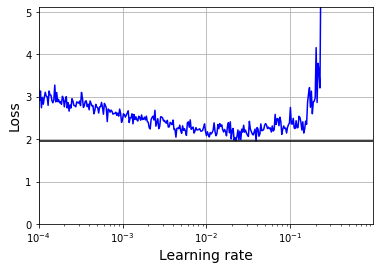

In [134]:
batch_size = 128
rates, losses = find_learning_rate(model, X_train_scaled, y_train, epochs=1,
                                   batch_size=batch_size)
plot_lr_vs_loss(rates, losses)

In [135]:
tf.random.set_seed(42)

model = tf.keras.Sequential()
model.add(tf.keras.layers.Flatten(input_shape=[32, 32, 3]))
for _ in range(20):
    model.add(tf.keras.layers.Dense(100,
                                 kernel_initializer="lecun_normal",
                                 activation="selu"))

model.add(tf.keras.layers.AlphaDropout(rate=0.1))
model.add(tf.keras.layers.Dense(10, activation="softmax"))

optimizer = tf.keras.optimizers.SGD(learning_rate=2e-2)
model.compile(loss="sparse_categorical_crossentropy",
              optimizer=optimizer,
              metrics=["accuracy"])

In [136]:
n_epochs = 15
n_iterations = math.ceil(len(X_train_scaled) / batch_size) * n_epochs
onecycle = OneCycleScheduler(n_iterations, max_lr=0.05)
history = model.fit(X_train_scaled, y_train, epochs=n_epochs, batch_size=batch_size,
                    validation_data=(X_valid_scaled, y_valid),
                    callbacks=[onecycle])

Epoch 1/15
352/352 [==============================] - 3s 7ms/step - loss: 2.0509 - accuracy: 0.2887 - val_loss: 1.8032 - val_accuracy: 0.3624
Epoch 2/15
352/352 [==============================] - 2s 7ms/step - loss: 1.7562 - accuracy: 0.3798 - val_loss: 1.6649 - val_accuracy: 0.4154
Epoch 3/15
352/352 [==============================] - 2s 7ms/step - loss: 1.6294 - accuracy: 0.4232 - val_loss: 1.6763 - val_accuracy: 0.4074
Epoch 4/15
352/352 [==============================] - 3s 7ms/step - loss: 1.5520 - accuracy: 0.4496 - val_loss: 1.6997 - val_accuracy: 0.4086
Epoch 5/15
352/352 [==============================] - 3s 7ms/step - loss: 1.5051 - accuracy: 0.4682 - val_loss: 1.6067 - val_accuracy: 0.4470
Epoch 6/15
352/352 [==============================] - 3s 7ms/step - loss: 1.4628 - accuracy: 0.4834 - val_loss: 1.5763 - val_accuracy: 0.4444
Epoch 7/15
352/352 [==============================] - 925s 3s/step - loss: 1.4226 - accuracy: 0.4965 - val_loss: 1.5800 - val_accuracy: 0.4540
Epoch

One cycle allowed us to train the model in just 15 epochs, each taking only 2 seconds (thanks to the larger batch size). This is several times faster than the fastest model we trained so far. Moreover, we improved the model's performance (from 50.7% to 52.0%).